Calcolo presenze per ogni base:
Basi analizzate: 3193

Presenze su s=3253 estrazioni 
per campioni di ampiezza alfa=60:

Analisi evidenze: (U(k), V(k), W(k), Y(k))
Statistiche sommari:

Valori per estratto singolo
- mean    : [23.95  5.91  0.09  6.52]
- median  : [24.  6.  0.  6.]
- mode    : [24  6  0  6], [ 278 2913 2913  915]
- std     : [4.49 0.3  0.3  1.45]
- skewness: [ 0.13 -3.36  3.36  0.51]
- q1      : [21.  6.  0.  6.]
- q3      : [27.  6.  0.  7.]
  Distribuzione asimmetrica: 
  (media e deviazione standard):
    Totale presenze                      [range U(k)]: 19.0 .. 28.0, copertura: 73.44%
    Combinazioni con almeno una presenza [range V(k)]: 6.0 .. 6.0, copertura: 91.23%
    Combinazioni senza presenze          [range W(k)]: -0.0 .. 0.0, copertura: 91.23%
    Massima frequenza di presenza        [range Y(k)]: 5.0 .. 8.0, copertura: 85.41%
  (quartili):
    Totale presenze                      [range U(k)]: 21.0 .. 27.0, copertura: 55.84%
    Combinazioni con almeno un

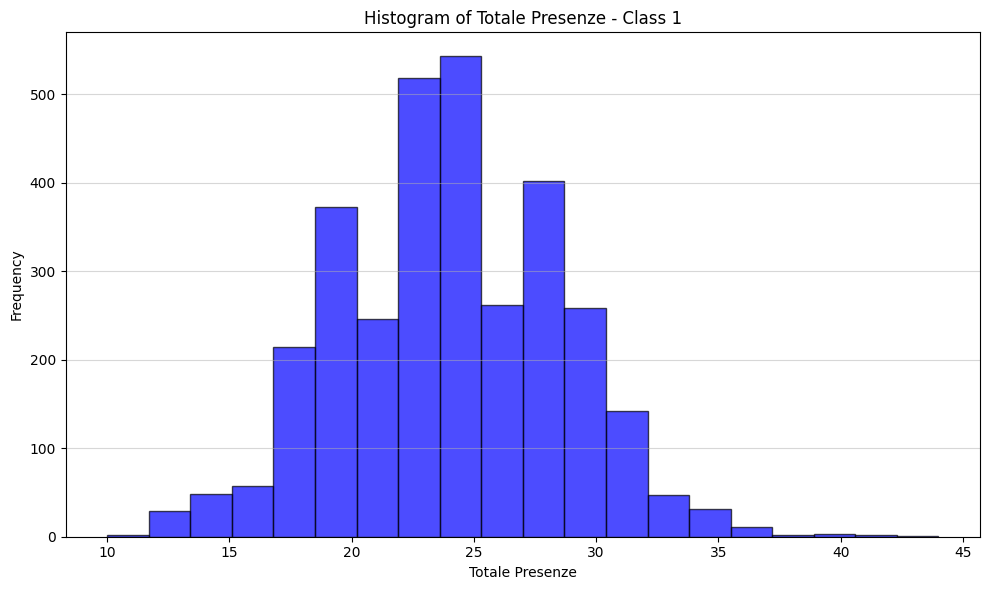

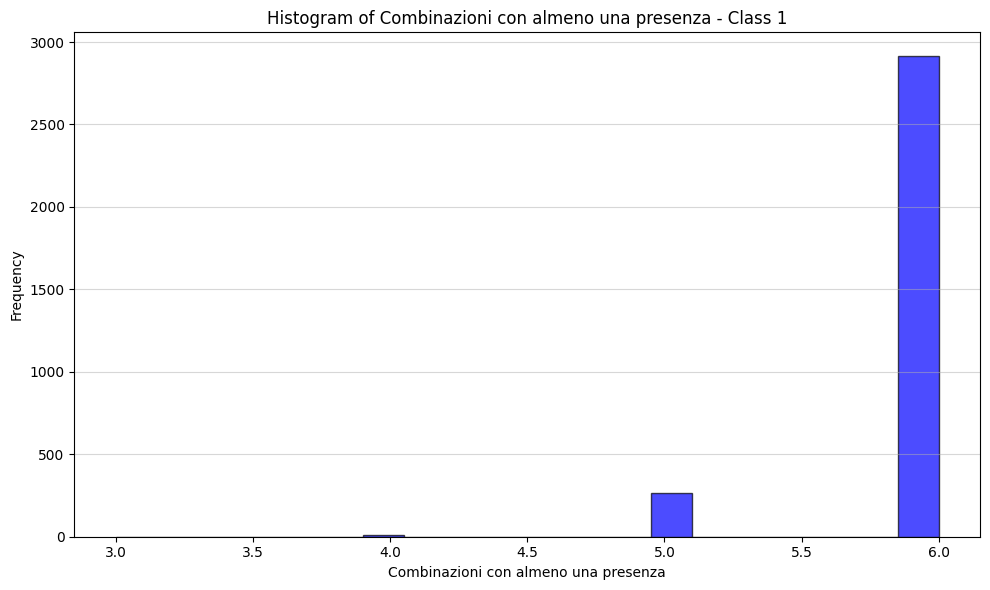

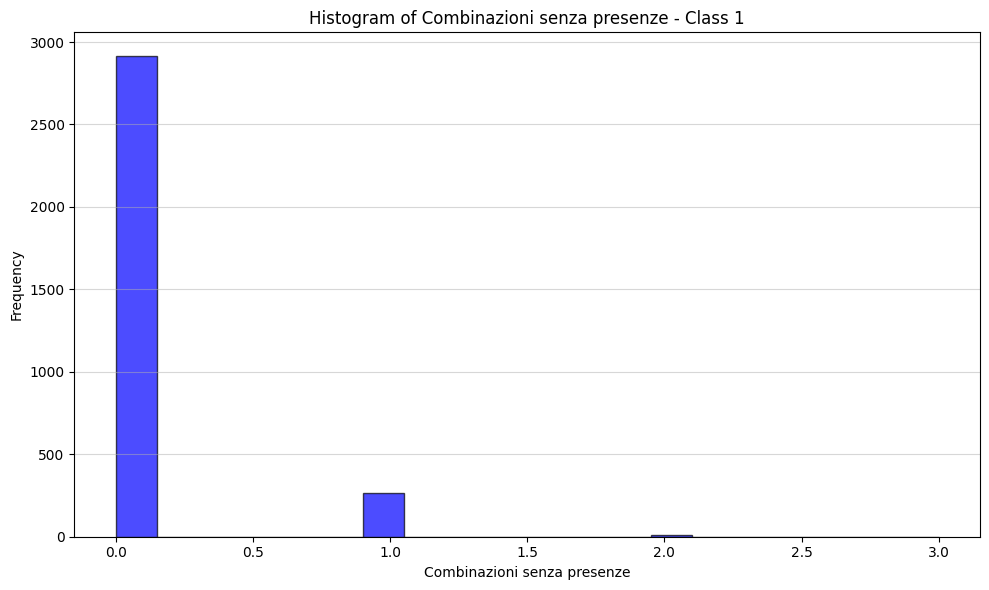

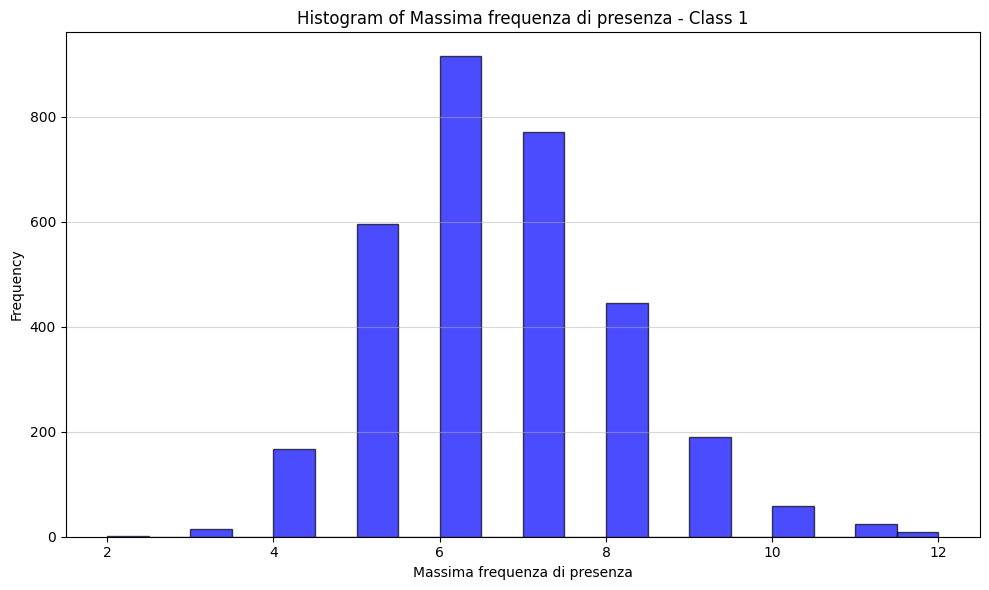

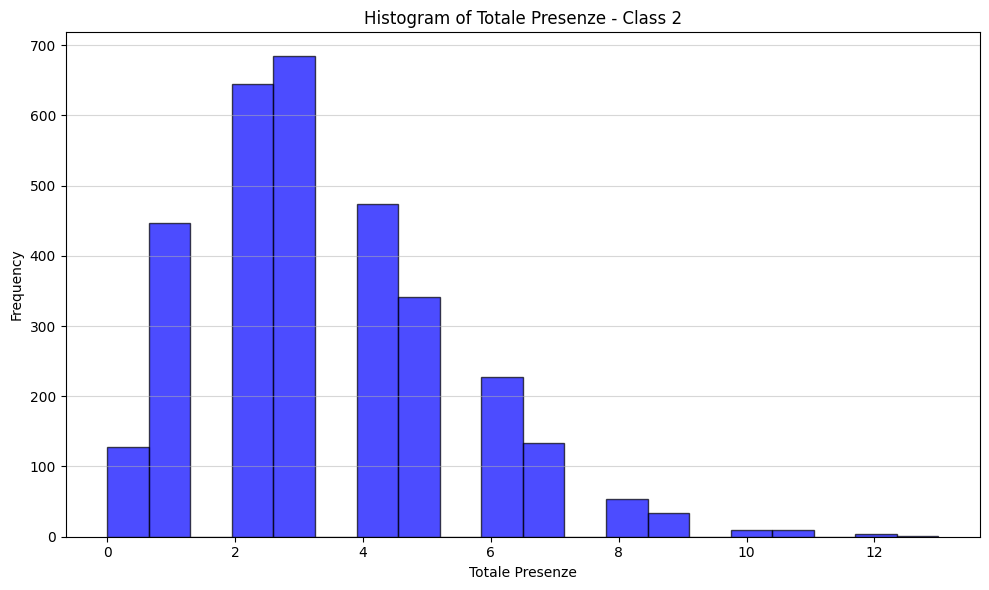

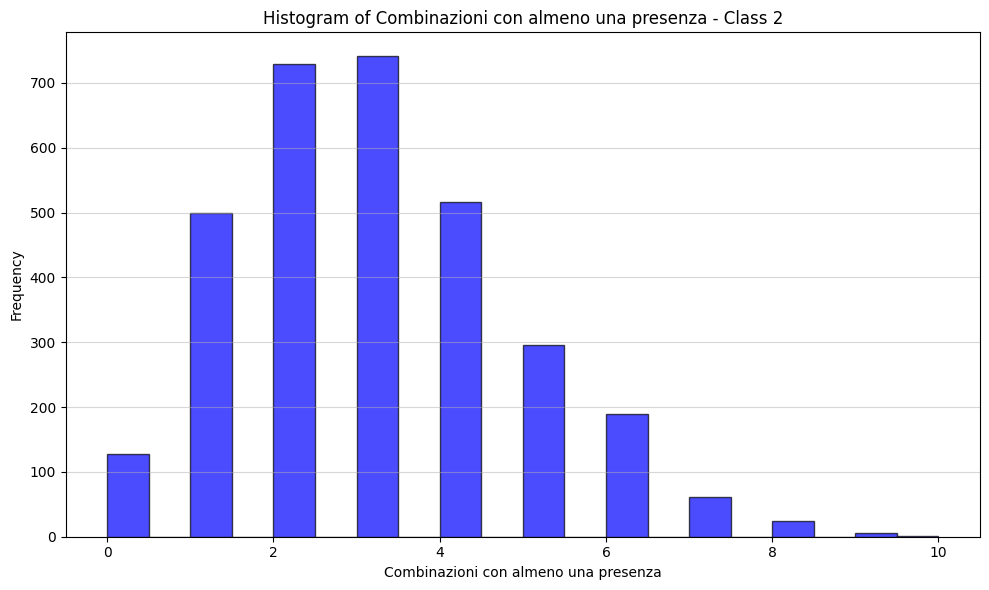

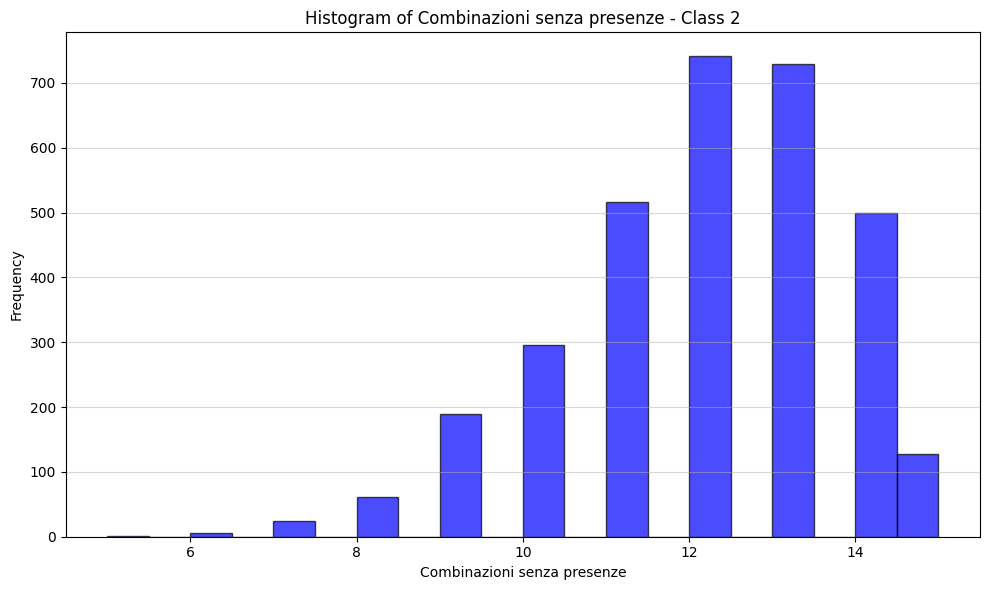

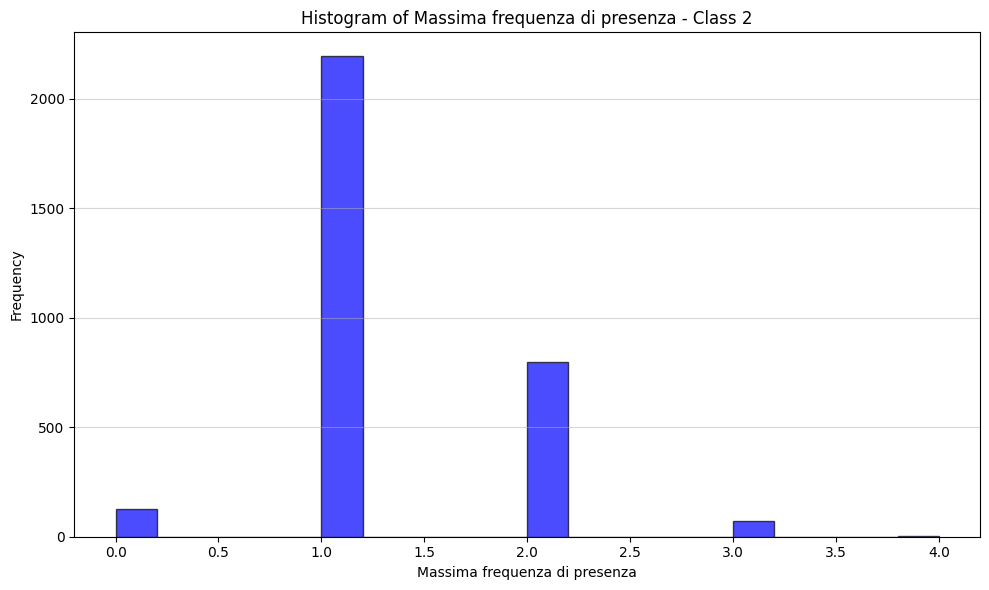

In [1]:
# Base di calcolo presenze di combinazioni di numeri in un intervallo storico di estrazioni della lotteria

# Il codice analizza le estrazioni della lotteria per determinare la frequenza di presenza di combinazioni di numeri in un intervallo storico, 
# utilizzando una base di calcolo rappresentata da una specifica estrazione.
# Il codice è strutturato per esaminare combinazioni di numeri da 1 a 6, calcolando la frequenza media di presenza per ciascuna classe di combinazioni 
# e fornendo un riassunto dei risultati.
# Il codice utilizza la libreria Lotteria per caricare le estrazioni, numpy per la manipolazione dei dati, itertools per generare le combinazioni 
# e scipy.special.comb per calcolare i coefficienti binomiali.     
#
# Il codice carica un file CSV contenente le estrazioni della lotteria, seleziona una base di calcolo (la prima estrazione) e un 
# intervallo storico (le estrazioni successive alla base).
# Per ogni classe di combinazioni (da 1 a 6 numeri), il codice calcola le combinazioni possibili della base, 
# conta quante volte ciascuna combinazione appare nell'intervallo storico e calcola la frequenza media di presenza per ogni classe di combinazioni. 
# Infine, stampa i risultati riassuntivi per ogni classe di combinazioni, inclusi
# il numero totale di presenze, il numero di combinazioni con almeno una presenza, la massima frequenza di presenza e la frequenza media.
# 
# Nota: il codice utilizza la libreria Lotteria per caricare le estrazioni, numpy per la manipolazione dei dati, 
# itertools per generare le combinazioni e scipy.special.comb per calcolare i coefficienti binomiali.
#
# Il file CSV deve essere formattato correttamente con le estrazioni della lotteria, e il percorso del file deve essere specificato correttamente nella variabile `file_estrazione`.
# 
# Esempio di output:
# base
# [1, 2, 3, 4, 5, 6]
# Combinazioni di classe 1:
# - Presenze: [10, 15, 20, 25, 30, 35]
# - Valori riassuntivi: [135, 6, 35, 22.5]
# Combinazioni di classe 2:
# - Presenze: [5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60, 65, 70, 75]
# - Valori riassuntivi: [600, 15, 75, 40.0]
# ...   
from lotteria import Lotteria
import numpy as np
from itertools import combinations
from scipy.special import comb
from scipy import stats
import matplotlib.pyplot as plt
from rebase_lib import RebaseLib

def print_dati_grafico(s,i):    
    for j in range(0,4):
        vx = [x[j] for x in s]
        print(f"\nElenco colonna {j+1} per classe k {i+1}:")
        (uniq, freq) = (np.unique(vx, return_counts=True))
        print(np.column_stack((uniq,freq)))
        
def  draw_histogram(data, k, description):
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.hist(data, bins=20, color='blue', edgecolor='black', alpha=0.7)
    ax.set_title(f'Histogram of {description} - Class {k+1}')
    ax.set_xlabel(f'{description}')
    ax.set_ylabel('Frequency')
    ax.grid(axis='y', alpha=0.5)
    plt.tight_layout()
    plt.show()

##############################################################################

file_estrazione = "./data/estrazioni_2026_2006.csv"
ll = Lotteria(file_estrazione)
rl = RebaseLib()

# Popolazione
storico_estrazioni = ll.carica_storico() # Carica le estrazioni da un file CSV
# Intervalli di campionamento
size_campione = 60

# Frequenza presenze per intervallo di campionamento   
print("Calcolo presenze per ogni base:")     
presenze = rl.calcolo_presenze(storico_estrazioni, size_campione)
print("Basi analizzate:", len(storico_estrazioni) - size_campione)

#  Sommario dei risultati per ogni classe di combinazioni
print(f"\nPresenze su s={len(storico_estrazioni)} estrazioni \nper campioni di ampiezza alfa={size_campione}:")
sommari = rl.calcolo_sommari(presenze)

# Stampa dei risultati riassuntivi per ogni classe di combinazioni
print ("\nAnalisi evidenze: (U(k), V(k), W(k), Y(k))") 
rl.statistiche_sommari(sommari)
        
        #print(f"    Somma dei sommari filtrati per classe k={i+1}: {risultato}")
        #print(f"    Copertura percentuale: {copertura}")
        
print("\nsommario completo.")

# Histogram
descr = ['Totale Presenze', 'Combinazioni con almeno una presenza', 'Combinazioni senza presenze', 'Massima frequenza di presenza'] 
for k in range(0,2):
    for j in range(0,4):
        data_column = [s[j] for s in sommari[k]]
        draw_histogram(data_column, k, descr[j])

        

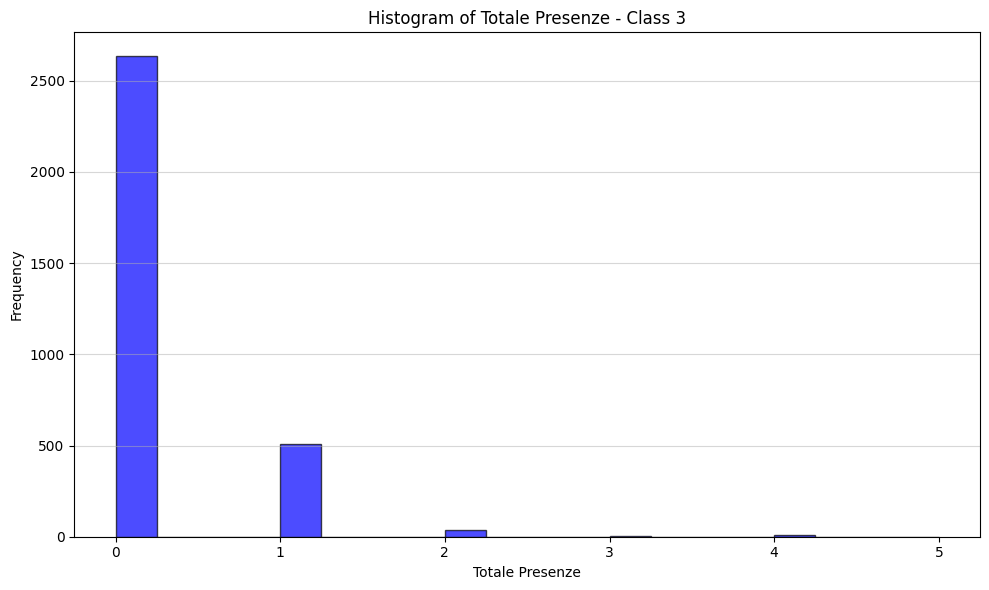

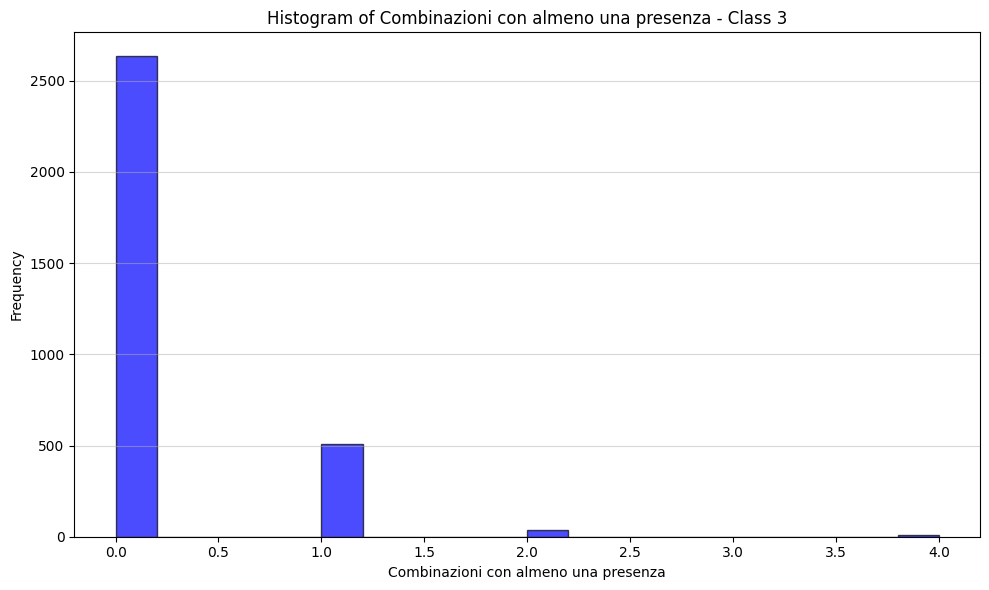

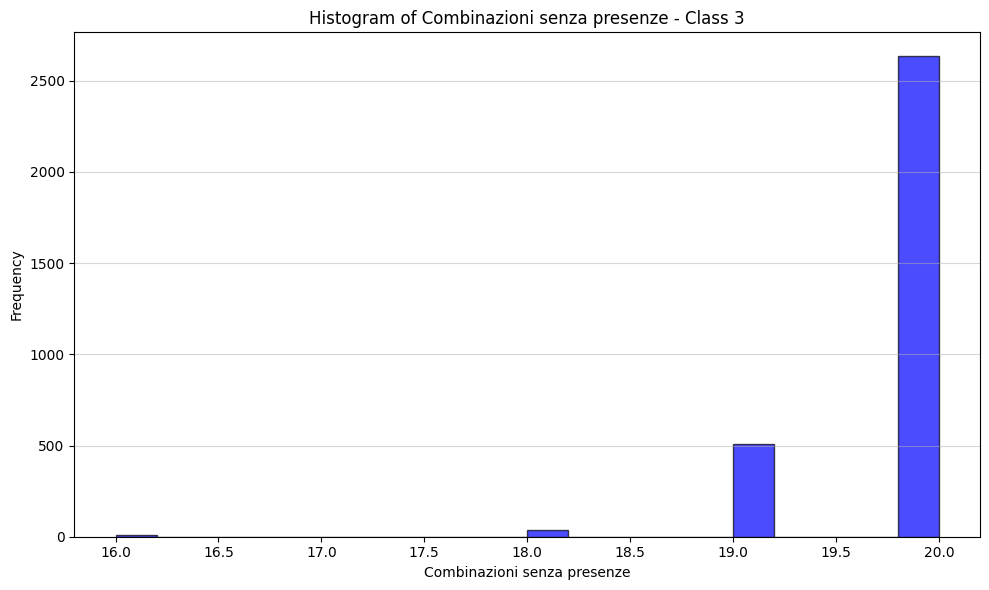

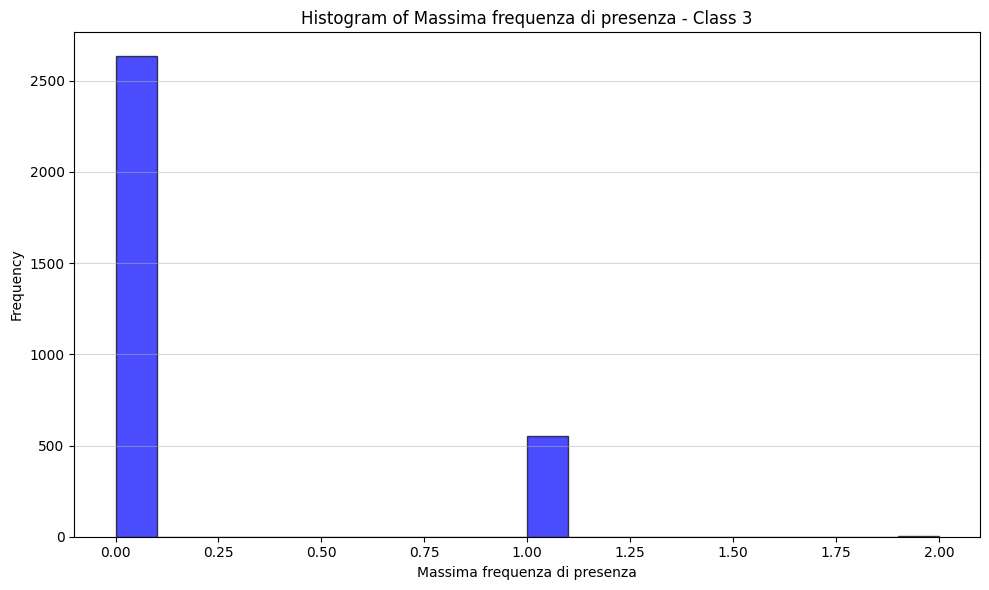

In [4]:
descr = ['Totale Presenze', 'Combinazioni con almeno una presenza', 'Combinazioni senza presenze', 'Massima frequenza di presenza'] 
k = 2
for j in range(0,4):
    data_column = [s[j] for s in sommari[k]]
    draw_histogram(data_column, k, descr[j])

In [3]:
import numpy as np

base = np.array([33, 34, 35, 58, 89, 90])

print("Base:", base)
print(base[1:])
print(base[:-1])
# Confronta ogni elemento con il successivo per verificare se la differenza è maggiore di 1
y = (base[1:] - base[:-1]) > 1
print ("y:", y)
# np.where restituisce gli indici degli elementi che soddisfano la condizione specificata
i = np.append(np.where(y), len(base) - 1)
print("i:", i)
print("boh:", np.append(-1, i))
# np.diff calcola la differenza tra elementi consecutivi di un array
# out[i] = a[i+1] - a[i]
z = np.diff(np.append(-1, i))
print("z:", z)
# np.bincount conta il numero di occorrenze di ogni valore intero in un array
b = np.bincount(z)
print("b:", b)
   
arr = np.zeros(6, dtype=int)
for i, v in enumerate(b):
    if i >= 2:
        arr[i-2] = v
arr[5] = sum(arr)
       
print("sequenze di lunghezza 2:", arr[0])
print("sequenze di lunghezza 3:", arr[1])
print("sequenze di lunghezza 4:", arr[2])
print("sequenze di lunghezza 5:", arr[3])
print("sequenze di lunghezza 6:", arr[4])
print("totale sequenze:", arr[5])

Base: [33 34 35 58 89 90]
[34 35 58 89 90]
[33 34 35 58 89]
y: [False False  True  True False]
i: [2 3 5]
boh: [-1  2  3  5]
z: [3 1 2]
b: [0 1 1 1]
sequenze di lunghezza 2: 1
sequenze di lunghezza 3: 1
sequenze di lunghezza 4: 0
sequenze di lunghezza 5: 0
sequenze di lunghezza 6: 0
totale sequenze: 2


In [ ]:
import numpy as np

min_val = np.array([3.72, 2.7, 0.96, 1.46])
max_val = np.array([8.2, 5.04, 3.3, 3.14])
count_array= np.array([ 239, 1355, 3103, 2748, 2013, 1432,  818,  477,  341,  212,  126,   51,   27,    6, 4])  # Example count array for demonstration
print("pippo: ", min_val, max_val)
print("pippo round: ", np.round(min_val, 0), np.round(max_val, 0))

# Use np.maximum and np.minimum for element-wise operations on arrays
min_idx = np.maximum(0, np.round(min_val, 0)).astype(int)
max_idx = np.minimum(len(count_array) - 1, np.round(max_val, 0)).astype(int)  # Assuming count_array has length 15 for this example

print("pippo1: ", min_idx, max_idx)

if np.any(min_idx > max_idx):
    print("Invalid range!")
    
sum_range = np.sum(count_array[min_idx:max_idx + 1])
    
print(sommari)# Extract the first column (Totale Presenze) from sommari
print([s[0] for s in sommari[0]])  # Print the first class of sommari
# Extract first column (Totale Presenze) for each class, handling empty lists
for k in range(len(sommari)):
    if sommari[k]:  # Check if list is not empty
        first_col = [s[0] for s in sommari[k]]
        print(f"Classe {k+1} - Totale Presenze: {first_col}")
    


pippo:  [3.72 2.7  0.96 1.46] [8.2  5.04 3.3  3.14]
pippo round:  [4. 3. 1. 1.] [8. 5. 3. 3.]
pippo1:  [4 3 1 1] [8 5 3 3]
[[[8, 5, 1, 2], [5, 3, 3, 3], [6, 3, 3, 3], [5, 4, 2, 2], [9, 6, 0, 2], [6, 4, 2, 3], [8, 4, 2, 3], [3, 3, 3, 1], [5, 4, 2, 2], [7, 5, 1, 2], [2, 1, 5, 2], [4, 4, 2, 1], [3, 2, 4, 2], [6, 4, 2, 2], [6, 4, 2, 2], [6, 4, 2, 2], [10, 6, 0, 3], [5, 4, 2, 2], [4, 4, 2, 1], [5, 3, 3, 2], [7, 4, 2, 2], [6, 5, 1, 2], [3, 2, 4, 2], [5, 4, 2, 2], [6, 4, 2, 2], [6, 4, 2, 2], [4, 3, 3, 2], [6, 3, 3, 3], [9, 5, 1, 3], [4, 4, 2, 1], [5, 4, 2, 2], [9, 5, 1, 3], [9, 5, 1, 4], [3, 2, 4, 2], [7, 3, 3, 4], [10, 6, 0, 3], [11, 5, 1, 3], [5, 4, 2, 2], [5, 3, 3, 3], [9, 6, 0, 3], [4, 4, 2, 1], [6, 4, 2, 2], [7, 5, 1, 2], [6, 4, 2, 3], [8, 6, 0, 2], [8, 5, 1, 2], [6, 4, 2, 3], [1, 1, 5, 1], [5, 3, 3, 2], [3, 3, 3, 1], [4, 4, 2, 1], [6, 4, 2, 2], [7, 4, 2, 3], [6, 3, 3, 4], [7, 4, 2, 3], [3, 3, 3, 1], [4, 3, 3, 2], [2, 2, 4, 1], [10, 6, 0, 3], [7, 5, 1, 2], [6, 4, 2, 2], [2, 2, 4, 1], [4,

In [ ]:
import numpy as np

arr = [[[8, 5, 1, 2], [5, 3, 3, 3], [6, 3, 3, 3], [5, 4, 2, 2], [9, 6, 0, 2], [6, 4, 2, 3], [8, 4, 2, 3], [3, 3, 3, 1], [5, 4, 2, 2], [7, 5, 1, 2], [2, 1, 5, 2], [4, 4, 2, 1], [3, 2, 4, 2], [6, 4, 2, 2], [6, 4, 2, 2], [6, 4, 2, 2], [10, 6, 0, 3], [5, 4, 2, 2], [4, 4, 2, 1], [5, 3, 3, 2], [7, 4, 2, 2], [6, 5, 1, 2], [3, 2, 4, 2], [5, 4, 2, 2], [6, 4, 2, 2], [6, 4, 2, 2], [4, 3, 3, 2], [6, 3, 3, 3], [9, 5, 1, 3], [4, 4, 2, 1], [5, 4, 2, 2], [9, 5, 1, 3], [9, 5, 1, 4], [3, 2, 4, 2], [7, 3, 3, 4], [10, 6, 0, 3], [11, 5, 1, 3], [5, 4, 2, 2], [5, 3, 3, 3], [9, 6, 0, 3], [4, 4, 2, 1], [6, 4, 2, 2], [7, 5, 1, 2], [6, 4, 2, 3], [8, 6, 0, 2], [8, 5, 1, 2], [6, 4, 2, 3], [1, 1, 5, 1], [5, 3, 3, 2], [3, 3, 3, 1], [4, 4, 2, 1], [6, 4, 2, 2], [7, 4, 2, 3], [6, 3, 3, 4], [7, 4, 2, 3], [3, 3, 3, 1], [4, 3, 3, 2], [2, 2, 4, 1], [10, 6, 0, 3], [7, 5, 1, 2], [6, 4, 2, 2], [2, 2, 4, 1], [4, 3, 3, 2], [7, 4, 2, 2], [5, 3, 3, 3], [2, 1, 5, 2], [6, 4, 2, 3], [9, 4, 2, 4], [7, 4, 2, 3], [10, 4, 2, 3], [9, 6, 0, 3], [9, 5, 1, 3], [6, 4, 2, 2], [4, 3, 3, 2], [8, 5, 1, 3], [1, 1, 5, 1], [10, 6, 0, 3], [7, 4, 2, 3], [6, 4, 2, 2], [10, 6, 0, 3], [4, 2, 4, 2], [4, 3, 3, 2], [6, 4, 2, 2], [6, 4, 2, 2], [5, 3, 3, 3], [6, 4, 2, 2], [6, 4, 2, 2], [8, 5, 1, 2], [3, 3, 3, 1], [7, 4, 2, 3], [8, 5, 1, 2], [5, 4, 2, 2], [2, 1, 5, 2], [5, 2, 4, 4], [5, 4, 2, 2], [8, 5, 1, 3], [7, 5, 1, 2], [8, 5, 1, 3], [4, 4, 2, 1], [7, 4, 2, 3], [7, 3, 3, 3], [7, 5, 1, 2], [6, 4, 2, 3], [7, 4, 2, 3], [2, 2, 4, 1], [8, 5, 1, 2], [9, 5, 1, 3], [7, 5, 1, 2], [5, 3, 3, 2], [6, 3, 3, 3], [6, 5, 1, 2], [5, 3, 3, 2], [6, 3, 3, 3], [2, 2, 4, 1], [4, 4, 2, 1], [3, 2, 4, 2], [7, 4, 2, 2], [6, 2, 4, 4], [8, 5, 1, 3], [8, 5, 1, 3], [7, 5, 1, 3], [5, 3, 3, 2], [8, 5, 1, 3], [7, 5, 1, 2], [6, 5, 1, 2], [6, 3, 3, 4], [5, 3, 3, 2], [7, 4, 2, 3], [5, 4, 2, 2], [6, 5, 1, 2], [12, 6, 0, 5], [12, 5, 1, 4], [9, 5, 1, 2], [6, 4, 2, 2], [5, 3, 3, 2], [6, 5, 1, 2], [7, 4, 2, 3], [5, 4, 2, 2], [9, 5, 1, 3], [8, 5, 1, 2], [6, 4, 2, 2], [8, 4, 2, 3], [6, 5, 1, 2], [5, 4, 2, 2], [5, 4, 2, 2], [7, 5, 1, 2], [7, 3, 3, 3], [8, 5, 1, 2], [5, 3, 3, 2], [4, 3, 3, 2], [5, 3, 3, 3], [7, 5, 1, 2], [12, 5, 1, 4], [9, 6, 0, 2], [3, 3, 3, 1], [7, 3, 3, 3], [3, 3, 3, 1], [6, 3, 3, 3], [5, 4, 2, 2], [11, 6, 0, 3], [13, 6, 0, 3], [7, 4, 2, 3], [6, 5, 1, 2], [6, 4, 2, 2], [5, 4, 2, 2], [4, 4, 2, 1], [7, 5, 1, 2], [6, 5, 1, 2], [4, 4, 2, 1], [7, 5, 1, 2], [2, 2, 4, 1], [6, 5, 1, 2], [3, 3, 3, 1], [3, 3, 3, 1], [8, 5, 1, 3], [8, 4, 2, 2], [5, 2, 4, 3], [4, 2, 4, 2], [6, 5, 1, 2], [7, 5, 1, 2], [8, 5, 1, 3], [5, 4, 2, 2], [1, 1, 5, 1], [3, 3, 3, 1], [10, 5, 1, 3], [10, 5, 1, 3], [5, 5, 1, 1], [9, 3, 3, 5], [4, 3, 3, 2], [8, 5, 1, 3], [12, 6, 0, 5], [6, 4, 2, 3], [7, 4, 2, 3], [10, 5, 1, 4], [5, 3, 3, 2], [6, 2, 4, 4], [2, 1, 5, 2], [12, 5, 1, 4], [5, 4, 2, 2], [10, 5, 1, 4], [7, 5, 1, 2], [6, 5, 1, 2], [8, 5, 1, 3], [4, 4, 2, 1], [5, 4, 2, 2], [3, 2, 4, 2], [4, 3, 3, 2], [5, 4, 2, 2], [3, 3, 3, 1], [6, 4, 2, 3], [8, 4, 2, 3], [4, 3, 3, 2], [7, 5, 1, 2], [6, 6, 0, 1], [7, 4, 2, 3], [5, 4, 2, 2], [3, 2, 4, 2], [7, 4, 2, 3], [7, 5, 1, 2], [4, 3, 3, 2], [3, 3, 3, 1], [7, 6, 0, 2], [4, 2, 4, 2], [3, 3, 3, 1], [5, 4, 2, 2], [7, 4, 2, 3], [4, 4, 2, 1], [6, 5, 1, 2], [1, 1, 5, 1], [4, 4, 2, 1], [5, 3, 3, 2], [4, 3, 3, 2], [8, 6, 0, 2], [7, 5, 1, 2], [4, 3, 3, 2], [7, 5, 1, 3], [6, 4, 2, 2], [6, 4, 2, 2], [5, 3, 3, 3], [3, 3, 3, 1], [8, 4, 2, 3], [7, 5, 1, 3], [8, 5, 1, 2], [3, 3, 3, 1], [4, 2, 4, 2], [4, 4, 2, 1], [3, 3, 3, 1], [2, 2, 4, 1], [9, 6, 0, 2], [6, 3, 3, 3], [8, 5, 1, 2], [3, 2, 4, 2], [8, 5, 1, 3], [5, 4, 2, 2], [2, 2, 4, 1], [3, 2, 4, 2], [6, 4, 2, 2], [7, 4, 2, 3], [7, 5, 1, 2], [6, 4, 2, 3], [8, 5, 1, 3], [6, 5, 1, 2], [10, 5, 1, 3], [9, 5, 1, 3], [7, 4, 2, 2], [7, 4, 2, 3], [4, 3, 3, 2], [4, 4, 2, 1], [3, 3, 3, 1], [6, 5, 1, 2], [3, 2, 4, 2], [4, 3, 3, 2], [6, 5, 1, 2], [5, 4, 2, 2], [6, 5, 1, 2], [8, 6, 0, 3], [5, 3, 3, 2], [2, 2, 4, 1], [3, 3, 3, 1], [1, 1, 5, 1], [5, 4, 2, 2], [4, 3, 3, 2], [5, 5, 1, 1], [5, 3, 3, 2], [3, 3, 3, 1], [7, 5, 1, 2], [5, 3, 3, 3], [4, 3, 3, 2], [11, 5, 1, 3], [7, 5, 1, 3], [5, 4, 2, 2], [8, 4, 2, 3], [5, 4, 2, 2], [5, 3, 3, 3], [5, 3, 3, 3], [7, 4, 2, 3], [4, 3, 3, 2], [3, 3, 3, 1], [7, 5, 1, 2], [12, 6, 0, 4], [5, 3, 3, 3], [8, 4, 2, 4], [6, 3, 3, 2], [7, 4, 2, 4], [6, 4, 2, 3], [4, 3, 3, 2], [7, 3, 3, 4], [3, 3, 3, 1], [9, 3, 3, 3], [8, 5, 1, 2], [8, 4, 2, 3], [5, 3, 3, 2], [6, 4, 2, 2], [6, 6, 0, 1], [5, 3, 3, 2], [6, 5, 1, 2], [14, 5, 1, 5], [5, 3, 3, 2], [3, 3, 3, 1], [7, 5, 1, 2], [9, 5, 1, 4], [10, 5, 1, 3], [6, 4, 2, 2], [6, 3, 3, 2], [5, 3, 3, 2], [7, 5, 1, 2], [4, 4, 2, 1], [9, 6, 0, 2], [8, 5, 1, 3], [2, 2, 4, 1], [7, 4, 2, 3], [6, 5, 1, 2], [8, 5, 1, 4], [4, 4, 2, 1], [4, 3, 3, 2], [5, 2, 4, 3], [6, 3, 3, 4], [5, 2, 4, 3], [7, 5, 1, 2], [6, 4, 2, 3], [10, 5, 1, 3], [6, 5, 1, 2], [9, 5, 1, 3], [8, 5, 1, 3], [4, 3, 3, 2], [6, 4, 2, 2], [7, 5, 1, 2], [5, 4, 2, 2], [2, 1, 5, 2], [5, 3, 3, 3], [5, 5, 1, 1], [9, 4, 2, 3], [10, 5, 1, 3], [5, 4, 2, 2], [6, 4, 2, 2], [9, 4, 2, 3], [7, 4, 2, 3], [5, 4, 2, 2], [5, 4, 2, 2], [3, 2, 4, 2], [10, 6, 0, 3], [5, 3, 3, 2], [7, 6, 0, 2], [6, 4, 2, 2], [6, 3, 3, 3], [7, 4, 2, 3], [3, 3, 3, 1], [6, 4, 2, 2], [5, 4, 2, 2], [2, 1, 5, 2], [5, 3, 3, 2], [10, 5, 1, 3], [8, 4, 2, 2], [3, 3, 3, 1], [4, 4, 2, 1], [5, 4, 2, 2], [3, 3, 3, 1], [5, 4, 2, 2], [6, 4, 2, 3], [7, 5, 1, 2], [5, 5, 1, 1], [8, 3, 3, 5], [11, 5, 1, 4], [2, 1, 5, 2], [3, 3, 3, 1], [4, 4, 2, 1], [6, 4, 2, 2], [4, 3, 3, 2], [3, 2, 4, 2], [6, 3, 3, 3], [8, 4, 2, 3], [3, 3, 3, 1], [9, 5, 1, 4], [4, 3, 3, 2], [4, 4, 2, 1], [6, 4, 2, 2], [4, 3, 3, 2], [7, 3, 3, 3], [9, 5, 1, 3], [10, 6, 0, 3], [8, 6, 0, 2], [7, 4, 2, 4], [8, 4, 2, 3], [9, 5, 1, 3], [7, 5, 1, 2], [6, 4, 2, 2], [6, 6, 0, 1], [5, 4, 2, 2], [6, 5, 1, 2], [3, 2, 4, 2], [7, 5, 1, 2], [1, 1, 5, 1], [2, 2, 4, 1], [2, 1, 5, 2], [4, 4, 2, 1], [4, 3, 3, 2], [5, 5, 1, 1], [6, 5, 1, 2], [5, 4, 2, 2], [7, 5, 1, 2], [6, 5, 1, 2], [6, 5, 1, 2], [3, 1, 5, 3], [4, 4, 2, 1], [7, 5, 1, 2], [5, 5, 1, 1], [1, 1, 5, 1], [4, 2, 4, 3], [2, 2, 4, 1], [7, 5, 1, 2], [8, 4, 2, 3], [6, 4, 2, 2], [4, 4, 2, 1], [3, 2, 4, 2], [5, 4, 2, 2], [6, 4, 2, 3], [6, 4, 2, 2], [8, 5, 1, 2], [8, 6, 0, 2], [11, 5, 1, 3], [7, 4, 2, 3], [7, 4, 2, 2], [8, 5, 1, 2], [6, 6, 0, 1], [3, 3, 3, 1], [2, 2, 4, 1], [6, 4, 2, 3], [9, 3, 3, 4], [3, 3, 3, 1], [6, 3, 3, 3], [4, 2, 4, 3], [4, 3, 3, 2], [10, 5, 1, 3], [7, 5, 1, 3], [8, 6, 0, 2], [4, 3, 3, 2], [6, 4, 2, 2], [8, 4, 2, 3], [8, 6, 0, 2], [8, 6, 0, 2], [5, 4, 2, 2], [3, 3, 3, 1], [6, 4, 2, 3], [5, 4, 2, 2], [3, 3, 3, 1], [6, 4, 2, 2], [3, 2, 4, 2], [3, 3, 3, 1], [5, 3, 3, 2], [6, 5, 1, 2], [8, 5, 1, 2], [5, 3, 3, 2], [4, 4, 2, 1], [4, 3, 3, 2], [4, 3, 3, 2], [3, 2, 4, 2], [9, 5, 1, 3], [2, 2, 4, 1], [3, 3, 3, 1], [5, 4, 2, 2], [6, 5, 1, 2], [8, 4, 2, 5], [8, 4, 2, 4], [6, 4, 2, 3], [6, 4, 2, 3], [4, 4, 2, 1], [3, 3, 3, 1], [10, 6, 0, 3], [8, 4, 2, 2], [6, 5, 1, 2], [6, 3, 3, 3], [5, 4, 2, 2], [4, 3, 3, 2], [4, 4, 2, 1], [7, 5, 1, 2], [2, 1, 5, 2], [7, 5, 1, 2], [10, 5, 1, 3], [7, 4, 2, 2], [7, 5, 1, 2], [5, 4, 2, 2], [8, 6, 0, 2], [7, 5, 1, 3], [4, 4, 2, 1], [10, 5, 1, 3], [4, 3, 3, 2], [5, 3, 3, 3], [4, 3, 3, 2], [9, 6, 0, 2], [7, 4, 2, 3], [5, 4, 2, 2], [6, 4, 2, 3], [3, 3, 3, 1], [4, 2, 4, 3], [7, 4, 2, 3], [1, 1, 5, 1], [8, 6, 0, 2], [9, 5, 1, 4], [9, 6, 0, 3], [3, 1, 5, 3], [7, 4, 2, 2], [13, 6, 0, 5], [7, 2, 4, 5], [4, 4, 2, 1], [4, 3, 3, 2], [12, 4, 2, 4], [10, 5, 1, 3], [8, 5, 1, 3], [6, 4, 2, 2], [3, 2, 4, 2], [9, 5, 1, 2], [4, 2, 4, 2], [7, 5, 1, 2], [6, 5, 1, 2], [1, 1, 5, 1], [3, 2, 4, 2], [4, 4, 2, 1], [4, 4, 2, 1], [10, 6, 0, 3], [1, 1, 5, 1], [7, 5, 1, 3], [10, 5, 1, 4], [4, 4, 2, 1], [5, 4, 2, 2], [7, 4, 2, 3], [5, 3, 3, 2], [5, 4, 2, 2], [4, 4, 2, 1], [3, 3, 3, 1], [4, 3, 3, 2], [5, 3, 3, 2], [8, 5, 1, 2], [6, 5, 1, 2], [4, 4, 2, 1], [6, 3, 3, 3], [6, 3, 3, 3], [7, 5, 1, 2], [5, 3, 3, 3], [9, 5, 1, 3], [7, 4, 2, 2], [8, 4, 2, 3], [7, 5, 1, 2], [7, 5, 1, 2], [10, 6, 0, 2], [10, 5, 1, 4], [8, 5, 1, 3], [8, 3, 3, 5], [2, 1, 5, 2], [7, 5, 1, 2], [12, 5, 1, 4], [5, 5, 1, 1], [7, 4, 2, 2], [6, 4, 2, 2], [9, 4, 2, 4], [4, 3, 3, 2], [9, 6, 0, 3], [4, 4, 2, 1], [4, 3, 3, 2], [5, 2, 4, 3], [3, 2, 4, 2], [10, 5, 1, 3], [5, 3, 3, 2], [9, 4, 2, 3], [12, 6, 0, 3], [8, 4, 2, 2], [4, 3, 3, 2], [10, 6, 0, 3], [9, 6, 0, 2], [6, 4, 2, 3], [10, 6, 0, 2], [3, 3, 3, 1], [7, 5, 1, 2], [8, 5, 1, 2], [9, 5, 1, 3], [5, 4, 2, 2], [4, 3, 3, 2], [6, 4, 2, 2], [8, 6, 0, 2], [6, 5, 1, 2], [7, 4, 2, 3], [3, 3, 3, 1], [4, 2, 4, 3], [3, 3, 3, 1], [11, 5, 1, 5], [7, 3, 3, 3], [8, 4, 2, 4], [8, 6, 0, 2], [4, 2, 4, 3], [7, 5, 1, 3], [7, 4, 2, 2], [10, 5, 1, 3], [4, 3, 3, 2], [11, 5, 1, 3], [9, 5, 1, 3], [8, 4, 2, 3], [6, 4, 2, 2], [8, 5, 1, 2], [11, 5, 1, 3], [8, 4, 2, 3], [8, 6, 0, 3], [3, 3, 3, 1], [5, 4, 2, 2], [4, 4, 2, 1], [5, 2, 4, 4], [8, 5, 1, 2], [9, 4, 2, 4], [4, 4, 2, 1], [4, 3, 3, 2], [7, 4, 2, 3], [6, 4, 2, 2], [4, 3, 3, 2], [6, 4, 2, 3], [6, 4, 2, 2], [7, 4, 2, 2], [5, 3, 3, 2], [8, 6, 0, 3], [6, 4, 2, 2], [4, 4, 2, 1], [4, 2, 4, 2], [5, 4, 2, 2], [5, 4, 2, 2], [9, 5, 1, 3], [6, 3, 3, 2], [8, 4, 2, 3], [6, 4, 2, 2], [8, 5, 1, 2], [5, 3, 3, 3], [5, 4, 2, 2], [2, 2, 4, 1], [6, 4, 2, 2], [5, 5, 1, 1], [11, 5, 1, 4], [8, 5, 1, 3], [8, 4, 2, 4], [5, 4, 2, 2], [4, 2, 4, 3], [6, 4, 2, 2], [4, 2, 4, 3], [3, 3, 3, 1], [4, 3, 3, 2], [10, 6, 0, 3], [5, 2, 4, 4], [7, 4, 2, 3], [4, 3, 3, 2], [5, 5, 1, 1], [6, 3, 3, 2], [7, 4, 2, 3], [8, 5, 1, 2], [6, 4, 2, 3], [2, 2, 4, 1], [8, 6, 0, 2], [8, 5, 1, 3], [9, 5, 1, 3], [3, 2, 4, 2], [8, 4, 2, 5], [6, 4, 2, 3], [7, 4, 2, 3], [2, 2, 4, 1], [8, 4, 2, 3], [14, 6, 0, 5], [3, 3, 3, 1], [6, 5, 1, 2], [5, 3, 3, 3], [3, 2, 4, 2], [8, 2, 4, 5], [5, 3, 3, 3], [7, 4, 2, 4], [10, 5, 1, 3], [6, 3, 3, 3], [9, 3, 3, 4], [7, 3, 3, 4], [4, 3, 3, 2], [6, 4, 2, 2], [9, 5, 1, 4], [6, 4, 2, 3], [5, 4, 2, 2], [5, 4, 2, 2], [3, 3, 3, 1], [4, 2, 4, 3], [6, 4, 2, 2], [3, 2, 4, 2], [9, 6, 0, 3], [4, 4, 2, 1], [5, 4, 2, 2], [4, 2, 4, 3], [14, 6, 0, 4], [11, 6, 0, 4], [4, 3, 3, 2], [6, 4, 2, 3], [3, 3, 3, 1], [3, 3, 3, 1], [7, 5, 1, 3], [5, 4, 2, 2], [6, 3, 3, 3], [3, 2, 4, 2], [6, 4, 2, 3], [5, 4, 2, 2], [3, 3, 3, 1], [1, 1, 5, 1], [8, 4, 2, 3], [7, 5, 1, 2], [4, 3, 3, 2], [8, 5, 1, 3], [13, 6, 0, 3], [7, 5, 1, 2], [7, 4, 2, 3], [7, 4, 2, 2], [8, 5, 1, 3], [6, 3, 3, 3], [7, 5, 1, 2], [9, 5, 1, 3], [6, 3, 3, 4], [5, 3, 3, 3], [4, 4, 2, 1], [7, 4, 2, 4], [2, 2, 4, 1], [5, 3, 3, 3], [7, 4, 2, 3], [10, 6, 0, 3], [7, 4, 2, 3], [3, 2, 4, 2], [9, 6, 0, 3], [5, 3, 3, 2], [4, 4, 2, 1], [10, 6, 0, 3], [8, 5, 1, 2], [7, 4, 2, 3], [3, 3, 3, 1], [5, 4, 2, 2], [7, 5, 1, 2], [3, 2, 4, 2], [4, 3, 3, 2], [3, 3, 3, 1], [7, 4, 2, 2], [6, 4, 2, 2], [5, 5, 1, 1], [4, 2, 4, 2], [6, 5, 1, 2], [7, 4, 2, 2], [6, 4, 2, 2], [8, 4, 2, 3], [7, 4, 2, 3], [2, 2, 4, 1], [1, 1, 5, 1], [7, 4, 2, 3], [5, 3, 3, 2], [5, 3, 3, 2], [4, 2, 4, 2], [5, 4, 2, 2], [9, 5, 1, 3], [7, 5, 1, 2], [5, 4, 2, 2], [6, 3, 3, 2], [8, 5, 1, 3], [6, 5, 1, 2], [9, 6, 0, 3], [7, 4, 2, 3], [8, 3, 3, 4], [5, 4, 2, 2], [9, 3, 3, 3], [4, 4, 2, 1], [8, 3, 3, 3], [5, 3, 3, 3], [8, 5, 1, 2], [7, 5, 1, 2], [7, 4, 2, 3], [5, 3, 3, 2], [5, 3, 3, 3], [3, 2, 4, 2], [4, 3, 3, 2], [3, 2, 4, 2], [9, 5, 1, 3], [9, 5, 1, 4], [3, 2, 4, 2], [9, 5, 1, 3], [5, 5, 1, 1], [2, 2, 4, 1], [6, 4, 2, 2], [8, 5, 1, 2], [2, 2, 4, 1], [6, 4, 2, 2], [3, 3, 3, 1], [6, 4, 2, 3], [4, 4, 2, 1], [9, 5, 1, 2], [6, 5, 1, 2], [6, 5, 1, 2], [5, 3, 3, 3], [8, 3, 3, 6], [5, 4, 2, 2], [5, 4, 2, 2], [11, 5, 1, 5], [2, 2, 4, 1], [5, 3, 3, 3], [3, 2, 4, 2], [7, 3, 3, 4], [5, 4, 2, 2], [4, 3, 3, 2], [6, 4, 2, 3], [9, 5, 1, 3], [4, 4, 2, 1], [6, 4, 2, 2], [1, 1, 5, 1], [4, 2, 4, 2], [7, 3, 3, 4], [7, 5, 1, 3], [9, 5, 1, 3], [7, 5, 1, 3], [7, 4, 2, 3], [8, 5, 1, 3], [6, 5, 1, 2], [6, 4, 2, 2], [5, 3, 3, 3], [4, 2, 4, 2], [4, 3, 3, 2], [9, 5, 1, 3], [7, 6, 0, 2], [4, 2, 4, 3], [5, 3, 3, 2], [8, 6, 0, 2], [6, 5, 1, 2], [3, 2, 4, 2], [4, 3, 3, 2], [7, 5, 1, 2], [8, 5, 1, 2], [10, 5, 1, 3], [5, 4, 2, 2], [5, 3, 3, 2], [9, 6, 0, 3], [2, 2, 4, 1], [4, 4, 2, 1], [8, 5, 1, 2], [3, 3, 3, 1], [9, 5, 1, 4], [9, 5, 1, 3], [5, 4, 2, 2], [4, 4, 2, 1], [6, 5, 1, 2], [4, 3, 3, 2], [5, 4, 2, 2], [5, 3, 3, 2], [7, 5, 1, 2], [7, 6, 0, 2], [2, 2, 4, 1], [5, 4, 2, 2], [9, 6, 0, 4], [2, 1, 5, 2], [3, 1, 5, 3], [6, 3, 3, 3], [2, 1, 5, 2], [7, 4, 2, 2], [4, 2, 4, 3], [6, 4, 2, 3], [9, 5, 1, 3], [5, 4, 2, 2], [6, 3, 3, 3], [10, 5, 1, 2], [5, 4, 2, 2], [4, 3, 3, 2], [6, 5, 1, 2], [6, 4, 2, 3], [3, 3, 3, 1], [7, 3, 3, 3], [2, 2, 4, 1], [5, 5, 1, 1], [6, 5, 1, 2], [5, 1, 5, 5], [8, 5, 1, 3], [11, 6, 0, 5], [3, 3, 3, 1], [5, 4, 2, 2], [9, 6, 0, 2], [4, 4, 2, 1], [3, 3, 3, 1], [8, 4, 2, 4], [9, 5, 1, 3], [3, 2, 4, 2], [7, 5, 1, 2], [8, 5, 1, 3], [3, 2, 4, 2], [2, 2, 4, 1], [5, 3, 3, 3], [7, 5, 1, 2], [8, 4, 2, 4], [5, 5, 1, 1], [5, 4, 2, 2], [11, 4, 2, 4], [5, 4, 2, 2], [13, 5, 1, 4], [3, 3, 3, 1], [9, 5, 1, 3], [2, 2, 4, 1], [7, 5, 1, 2], [5, 3, 3, 2], [7, 4, 2, 3], [1, 1, 5, 1], [5, 4, 2, 2], [5, 4, 2, 2], [5, 4, 2, 2], [8, 5, 1, 3], [4, 3, 3, 2], [4, 4, 2, 1], [4, 4, 2, 1], [5, 4, 2, 2], [7, 3, 3, 3], [7, 3, 3, 3], [8, 4, 2, 2], [5, 4, 2, 2], [4, 3, 3, 2], [7, 5, 1, 2], [6, 4, 2, 2], [1, 1, 5, 1], [7, 4, 2, 3], [6, 5, 1, 2], [7, 5, 1, 2], [5, 5, 1, 1], [3, 2, 4, 2], [1, 1, 5, 1], [8, 5, 1, 3], [4, 3, 3, 2], [12, 6, 0, 3], [10, 5, 1, 2], [6, 4, 2, 2], [3, 2, 4, 2], [8, 6, 0, 2], [4, 3, 3, 2], [6, 5, 1, 2], [6, 4, 2, 3], [2, 1, 5, 2], [2, 2, 4, 1], [3, 2, 4, 2], [8, 5, 1, 3], [7, 4, 2, 3], [4, 4, 2, 1], [5, 3, 3, 2], [4, 3, 3, 2], [10, 5, 1, 3], [5, 4, 2, 2], [6, 4, 2, 2], [3, 3, 3, 1], [6, 4, 2, 2], [4, 3, 3, 2], [8, 6, 0, 2], [2, 1, 5, 2], [5, 5, 1, 1], [4, 3, 3, 2], [7, 5, 1, 2], [8, 6, 0, 2], [6, 4, 2, 2], [4, 3, 3, 2], [7, 5, 1, 2], [8, 6, 0, 2], [5, 4, 2, 2], [6, 3, 3, 3], [7, 6, 0, 2], [9, 4, 2, 4], [3, 2, 4, 2], [7, 4, 2, 3], [3, 3, 3, 1], [5, 2, 4, 3], [5, 5, 1, 1], [4, 4, 2, 1], [6, 4, 2, 2], [9, 5, 1, 3], [5, 2, 4, 4], [4, 3, 3, 2], [10, 5, 1, 3], [6, 3, 3, 2], [8, 5, 1, 2], [4, 4, 2, 1], [6, 4, 2, 2], [6, 5, 1, 2], [7, 5, 1, 2], [3, 3, 3, 1], [4, 2, 4, 3], [12, 5, 1, 4], [5, 3, 3, 3], [7, 5, 1, 2], [5, 3, 3, 2], [7, 4, 2, 3], [8, 5, 1, 2], [5, 4, 2, 2], [4, 4, 2, 1], [3, 2, 4, 2], [2, 2, 4, 1], [7, 6, 0, 2], [5, 4, 2, 2], [5, 3, 3, 3], [5, 3, 3, 2], [4, 3, 3, 2], [5, 4, 2, 2], [5, 4, 2, 2], [4, 2, 4, 2], [5, 4, 2, 2], [6, 5, 1, 2], [7, 6, 0, 2], [5, 3, 3, 2], [2, 2, 4, 1], [6, 4, 2, 2], [3, 3, 3, 1], [8, 4, 2, 3], [4, 3, 3, 2], [4, 2, 4, 3], [5, 4, 2, 2], [3, 3, 3, 1], [8, 5, 1, 2], [7, 5, 1, 2], [5, 2, 4, 4], [7, 5, 1, 2], [2, 2, 4, 1], [7, 4, 2, 3], [5, 4, 2, 2], [5, 5, 1, 1], [6, 3, 3, 3], [8, 5, 1, 3], [4, 3, 3, 2], [3, 3, 3, 1], [3, 3, 3, 1], [6, 4, 2, 3], [5, 4, 2, 2], [7, 4, 2, 3], [11, 5, 1, 4], [2, 2, 4, 1], [4, 3, 3, 2], [12, 5, 1, 5], [6, 4, 2, 3], [3, 2, 4, 2], [9, 6, 0, 4], [4, 3, 3, 2], [5, 4, 2, 2], [6, 4, 2, 2], [5, 4, 2, 2], [6, 3, 3, 3], [5, 3, 3, 3], [7, 4, 2, 2], [4, 3, 3, 2], [3, 3, 3, 1], [4, 3, 3, 2], [7, 5, 1, 2], [4, 4, 2, 1], [9, 4, 2, 3], [3, 3, 3, 1], [7, 4, 2, 2], [8, 5, 1, 3], [7, 5, 1, 2], [2, 2, 4, 1], [3, 2, 4, 2], [7, 4, 2, 3], [6, 5, 1, 2], [9, 5, 1, 5], [7, 4, 2, 2], [4, 4, 2, 1], [7, 3, 3, 3], [8, 4, 2, 4], [3, 3, 3, 1], [9, 4, 2, 3], [5, 4, 2, 2], [7, 4, 2, 2], [9, 6, 0, 2], [6, 4, 2, 2], [6, 4, 2, 3], [5, 2, 4, 4], [7, 5, 1, 2], [7, 5, 1, 3], [4, 3, 3, 2], [5, 3, 3, 2], [8, 4, 2, 4], [6, 4, 2, 2], [7, 4, 2, 3], [2, 2, 4, 1], [3, 3, 3, 1], [3, 3, 3, 1], [10, 5, 1, 4], [7, 4, 2, 3], [8, 6, 0, 3], [10, 5, 1, 2], [6, 5, 1, 2], [7, 6, 0, 2], [4, 4, 2, 1], [7, 4, 2, 3], [5, 3, 3, 3], [7, 4, 2, 3], [5, 4, 2, 2], [8, 5, 1, 2], [5, 3, 3, 2], [7, 5, 1, 2], [4, 4, 2, 1], [6, 6, 0, 1], [11, 6, 0, 3], [6, 5, 1, 2], [4, 3, 3, 2], [6, 4, 2, 3], [6, 4, 2, 2], [4, 3, 3, 2], [5, 5, 1, 1], [6, 4, 2, 3], [4, 3, 3, 2], [11, 5, 1, 4], [5, 4, 2, 2], [8, 4, 2, 3], [5, 4, 2, 2], [6, 4, 2, 2], [4, 3, 3, 2], [7, 5, 1, 2], [5, 2, 4, 3], [6, 3, 3, 3], [7, 4, 2, 3], [7, 4, 2, 3], [6, 3, 3, 2], [8, 5, 1, 2], [4, 4, 2, 1], [6, 5, 1, 2], [5, 4, 2, 2], [9, 5, 1, 3], [8, 5, 1, 3], [7, 4, 2, 2], [9, 5, 1, 3], [6, 3, 3, 2], [6, 4, 2, 2], [3, 3, 3, 1], [7, 5, 1, 2], [6, 3, 3, 4], [6, 3, 3, 3], [2, 2, 4, 1], [3, 3, 3, 1], [6, 4, 2, 2], [5, 4, 2, 2], [4, 3, 3, 2], [3, 3, 3, 1], [7, 5, 1, 2], [11, 5, 1, 4], [9, 6, 0, 3], [6, 4, 2, 2], [3, 2, 4, 2], [10, 4, 2, 3], [8, 5, 1, 3], [5, 4, 2, 2], [6, 5, 1, 2], [9, 5, 1, 3], [5, 4, 2, 2], [5, 3, 3, 2], [7, 5, 1, 2], [5, 4, 2, 2], [5, 4, 2, 2], [6, 5, 1, 2], [6, 5, 1, 2], [6, 4, 2, 2], [6, 4, 2, 2], [2, 2, 4, 1], [1, 1, 5, 1], [7, 5, 1, 3], [8, 4, 2, 3], [6, 4, 2, 2], [7, 4, 2, 3], [3, 3, 3, 1], [9, 5, 1, 3], [6, 4, 2, 2], [4, 3, 3, 2], [5, 4, 2, 2], [6, 4, 2, 2], [4, 3, 3, 2], [9, 5, 1, 3], [7, 4, 2, 3], [9, 4, 2, 3], [8, 6, 0, 2], [5, 4, 2, 2], [7, 4, 2, 3], [10, 6, 0, 2], [6, 5, 1, 2], [7, 6, 0, 2], [5, 3, 3, 2], [3, 2, 4, 2], [5, 5, 1, 1], [4, 2, 4, 3], [3, 2, 4, 2], [6, 4, 2, 2], [10, 6, 0, 3], [4, 2, 4, 3], [5, 4, 2, 2], [6, 4, 2, 2], [2, 1, 5, 2], [7, 5, 1, 2], [5, 4, 2, 2], [7, 5, 1, 2], [7, 5, 1, 2], [4, 4, 2, 1], [4, 1, 5, 4], [8, 4, 2, 3], [9, 5, 1, 3], [4, 3, 3, 2], [2, 2, 4, 1], [5, 4, 2, 2], [8, 6, 0, 3], [8, 5, 1, 3], [7, 4, 2, 3], [4, 3, 3, 2], [3, 3, 3, 1], [7, 5, 1, 2], [3, 3, 3, 1], [8, 4, 2, 3], [7, 4, 2, 3], [7, 5, 1, 2], [2, 2, 4, 1], [4, 4, 2, 1], [2, 2, 4, 1], [6, 3, 3, 3], [10, 4, 2, 3], [8, 3, 3, 4], [4, 3, 3, 2], [4, 3, 3, 2], [5, 2, 4, 3], [7, 5, 1, 2], [6, 4, 2, 2], [12, 6, 0, 4], [5, 3, 3, 3], [8, 5, 1, 3], [5, 4, 2, 2], [3, 2, 4, 2], [7, 4, 2, 3], [9, 3, 3, 5], [9, 5, 1, 4], [7, 4, 2, 3], [4, 4, 2, 1], [10, 5, 1, 3], [7, 6, 0, 2], [5, 3, 3, 2], [5, 4, 2, 2], [6, 5, 1, 2], [7, 5, 1, 2], [4, 4, 2, 1], [7, 4, 2, 2], [5, 3, 3, 2], [7, 5, 1, 2], [3, 2, 4, 2], [5, 3, 3, 3], [2, 1, 5, 2], [3, 3, 3, 1], [8, 6, 0, 2], [7, 5, 1, 2], [2, 2, 4, 1], [4, 4, 2, 1], [5, 2, 4, 3], [1, 1, 5, 1], [7, 4, 2, 3], [7, 5, 1, 2], [9, 5, 1, 3], [3, 3, 3, 1], [7, 4, 2, 3], [7, 3, 3, 4], [4, 4, 2, 1], [10, 5, 1, 4], [3, 3, 3, 1], [6, 3, 3, 2], [4, 4, 2, 1], [9, 5, 1, 3], [5, 4, 2, 2], [5, 4, 2, 2], [6, 4, 2, 3], [6, 4, 2, 2], [6, 4, 2, 2], [1, 1, 5, 1], [8, 6, 0, 2], [7, 5, 1, 2], [5, 3, 3, 3], [4, 4, 2, 1], [5, 3, 3, 2], [3, 1, 5, 3], [7, 5, 1, 2], [5, 4, 2, 2], [8, 5, 1, 2], [4, 4, 2, 1], [8, 5, 1, 2], [4, 3, 3, 2], [7, 4, 2, 3], [8, 5, 1, 3], [5, 3, 3, 2], [7, 4, 2, 2], [6, 4, 2, 2], [5, 4, 2, 2], [11, 6, 0, 3], [3, 2, 4, 2], [7, 6, 0, 2], [5, 4, 2, 2], [4, 3, 3, 2], [8, 5, 1, 2], [6, 5, 1, 2], [6, 5, 1, 2], [4, 3, 3, 2], [7, 4, 2, 2], [8, 4, 2, 3], [6, 5, 1, 2], [6, 4, 2, 3], [2, 2, 4, 1], [4, 3, 3, 2], [7, 4, 2, 2], [5, 3, 3, 2], [7, 4, 2, 3], [5, 4, 2, 2], [1, 1, 5, 1], [10, 5, 1, 3], [6, 4, 2, 2], [6, 4, 2, 2], [7, 5, 1, 2], [7, 4, 2, 3], [3, 3, 3, 1], [7, 5, 1, 3], [5, 3, 3, 3], [8, 6, 0, 3], [8, 5, 1, 3], [7, 5, 1, 2], [4, 4, 2, 1], [2, 1, 5, 2], [7, 5, 1, 3], [8, 5, 1, 2], [5, 4, 2, 2], [4, 2, 4, 3], [5, 3, 3, 2], [7, 5, 1, 2], [5, 3, 3, 3], [10, 5, 1, 2], [4, 4, 2, 1], [6, 4, 2, 2], [6, 5, 1, 2], [7, 4, 2, 3], [4, 4, 2, 1], [3, 2, 4, 2], [5, 3, 3, 3], [5, 4, 2, 2], [6, 5, 1, 2], [5, 5, 1, 1], [7, 4, 2, 3], [4, 3, 3, 2], [5, 4, 2, 2], [5, 4, 2, 2], [5, 3, 3, 3], [5, 4, 2, 2], [7, 5, 1, 3], [4, 3, 3, 2], [9, 5, 1, 3], [4, 2, 4, 2], [6, 4, 2, 2], [5, 3, 3, 2], [5, 4, 2, 2], [5, 3, 3, 2], [8, 4, 2, 3], [4, 3, 3, 2], [8, 5, 1, 3], [8, 5, 1, 3], [3, 2, 4, 2], [5, 3, 3, 3], [10, 5, 1, 3], [4, 3, 3, 2], [7, 4, 2, 2], [10, 6, 0, 3], [5, 4, 2, 2], [3, 3, 3, 1], [7, 5, 1, 2], [9, 6, 0, 2], [6, 4, 2, 2], [5, 4, 2, 2], [5, 3, 3, 2], [4, 4, 2, 1], [4, 3, 3, 2], [5, 3, 3, 2], [7, 4, 2, 4], [3, 3, 3, 1], [4, 3, 3, 2], [7, 4, 2, 2], [4, 4, 2, 1], [5, 5, 1, 1], [5, 3, 3, 3], [8, 4, 2, 3], [7, 5, 1, 2], [4, 2, 4, 3], [8, 4, 2, 3], [7, 4, 2, 2], [9, 6, 0, 2], [3, 3, 3, 1], [5, 3, 3, 3], [8, 5, 1, 2], [8, 5, 1, 3], [8, 4, 2, 3], [6, 4, 2, 3], [8, 4, 2, 3], [6, 4, 2, 2], [6, 4, 2, 2], [8, 5, 1, 2], [6, 4, 2, 3], [5, 3, 3, 2], [4, 3, 3, 2], [5, 4, 2, 2], [6, 5, 1, 2], [7, 4, 2, 3], [7, 5, 1, 2], [7, 5, 1, 2], [6, 3, 3, 4], [6, 4, 2, 3], [7, 4, 2, 2], [3, 3, 3, 1], [8, 4, 2, 3], [5, 4, 2, 2], [9, 5, 1, 5], [4, 2, 4, 3], [7, 3, 3, 4], [7, 4, 2, 3], [3, 3, 3, 1], [3, 3, 3, 1], [8, 5, 1, 3], [6, 3, 3, 3], [6, 3, 3, 2], [5, 4, 2, 2], [11, 6, 0, 3], [10, 5, 1, 4], [9, 6, 0, 2], [7, 4, 2, 3], [8, 4, 2, 3], [7, 5, 1, 2], [2, 2, 4, 1], [5, 3, 3, 3], [2, 2, 4, 1], [4, 3, 3, 2], [11, 6, 0, 3], [3, 3, 3, 1], [5, 3, 3, 2], [5, 4, 2, 2], [6, 3, 3, 2], [8, 4, 2, 3], [3, 2, 4, 2], [6, 5, 1, 2], [8, 5, 1, 2], [9, 5, 1, 3], [7, 4, 2, 2], [9, 6, 0, 2], [7, 5, 1, 3], [5, 5, 1, 1], [5, 4, 2, 2], [6, 4, 2, 2], [7, 5, 1, 2], [6, 3, 3, 3], [7, 5, 1, 2], [7, 5, 1, 2], [4, 2, 4, 3], [7, 4, 2, 2], [1, 1, 5, 1], [8, 5, 1, 3], [6, 4, 2, 3], [5, 3, 3, 2], [5, 4, 2, 2], [6, 4, 2, 3], [6, 4, 2, 2], [6, 4, 2, 3], [5, 4, 2, 2], [4, 4, 2, 1], [6, 4, 2, 2], [4, 3, 3, 2], [5, 2, 4, 4], [5, 4, 2, 2], [9, 4, 2, 3], [2, 2, 4, 1], [4, 3, 3, 2], [5, 3, 3, 3], [6, 4, 2, 2], [7, 4, 2, 3], [4, 3, 3, 2], [6, 4, 2, 3], [9, 3, 3, 4], [6, 4, 2, 3], [10, 4, 2, 5], [7, 4, 2, 4], [12, 5, 1, 4], [10, 4, 2, 4], [8, 4, 2, 3], [9, 5, 1, 4], [10, 4, 2, 3], [5, 3, 3, 2], [10, 6, 0, 3], [8, 5, 1, 2], [8, 5, 1, 2], [6, 5, 1, 2], [5, 4, 2, 2], [4, 3, 3, 2], [4, 4, 2, 1], [5, 4, 2, 2], [5, 4, 2, 2], [9, 5, 1, 4], [4, 3, 3, 2], [3, 3, 3, 1], [5, 3, 3, 3], [9, 6, 0, 3], [5, 3, 3, 3], [4, 2, 4, 3], [5, 3, 3, 2], [7, 4, 2, 3], [9, 6, 0, 2], [5, 5, 1, 1], [8, 5, 1, 3], [10, 6, 0, 3], [3, 2, 4, 2], [10, 6, 0, 2], [8, 5, 1, 2], [4, 4, 2, 1], [6, 5, 1, 2], [2, 2, 4, 1], [5, 3, 3, 2], [5, 5, 1, 1], [8, 6, 0, 2], [6, 4, 2, 2], [9, 5, 1, 3], [1, 1, 5, 1], [7, 5, 1, 2], [6, 5, 1, 2], [2, 2, 4, 1], [7, 4, 2, 3], [3, 3, 3, 1], [7, 3, 3, 4], [11, 5, 1, 3], [5, 5, 1, 1], [7, 4, 2, 3], [8, 4, 2, 3], [3, 3, 3, 1], [8, 3, 3, 4], [7, 4, 2, 4], [4, 3, 3, 2], [6, 3, 3, 3], [5, 3, 3, 2], [4, 3, 3, 2], [9, 5, 1, 2], [6, 4, 2, 3], [5, 3, 3, 2], [4, 2, 4, 3], [5, 5, 1, 1], [8, 6, 0, 2], [6, 4, 2, 2], [2, 1, 5, 2], [4, 4, 2, 1], [8, 5, 1, 3], [1, 1, 5, 1], [6, 4, 2, 2], [6, 5, 1, 2], [8, 5, 1, 3], [9, 5, 1, 3], [6, 3, 3, 2], [4, 2, 4, 2], [6, 4, 2, 3], [6, 4, 2, 3], [5, 4, 2, 2], [5, 3, 3, 2], [4, 2, 4, 2], [6, 5, 1, 2], [10, 6, 0, 3], [3, 2, 4, 2], [3, 3, 3, 1], [6, 4, 2, 2], [4, 3, 3, 2], [9, 4, 2, 4], [4, 2, 4, 3], [9, 6, 0, 3], [6, 4, 2, 2], [8, 5, 1, 3], [8, 5, 1, 3], [5, 4, 2, 2], [8, 3, 3, 3], [9, 5, 1, 3], [7, 4, 2, 3], [2, 2, 4, 1], [4, 3, 3, 2], [8, 5, 1, 4], [6, 4, 2, 2], [7, 4, 2, 3], [4, 2, 4, 2], [4, 3, 3, 2], [7, 4, 2, 3], [8, 5, 1, 3], [11, 6, 0, 3], [7, 3, 3, 4], [6, 3, 3, 3], [3, 2, 4, 2], [8, 6, 0, 2], [8, 6, 0, 2], [6, 4, 2, 3], [5, 3, 3, 2], [4, 3, 3, 2], [4, 3, 3, 2], [5, 3, 3, 3], [2, 2, 4, 1], [9, 4, 2, 4], [9, 4, 2, 3], [7, 5, 1, 3], [8, 5, 1, 2], [6, 5, 1, 2], [9, 5, 1, 2], [5, 4, 2, 2], [9, 6, 0, 2], [8, 5, 1, 3], [6, 4, 2, 3], [7, 6, 0, 2], [10, 6, 0, 3], [6, 4, 2, 2], [5, 3, 3, 2], [2, 2, 4, 1], [2, 2, 4, 1], [10, 5, 1, 3], [9, 6, 0, 3], [2, 2, 4, 1], [4, 3, 3, 2], [7, 5, 1, 2], [5, 4, 2, 2], [6, 4, 2, 3], [7, 4, 2, 3], [6, 3, 3, 3], [6, 3, 3, 2], [10, 4, 2, 3], [6, 5, 1, 2], [4, 3, 3, 2], [5, 3, 3, 2], [7, 6, 0, 2], [5, 4, 2, 2], [7, 5, 1, 2], [6, 4, 2, 3], [5, 4, 2, 2], [5, 4, 2, 2], [5, 3, 3, 2], [7, 4, 2, 3], [10, 4, 2, 4], [6, 4, 2, 2], [6, 3, 3, 2], [3, 3, 3, 1], [5, 3, 3, 2], [6, 4, 2, 3], [4, 2, 4, 2], [9, 5, 1, 3], [8, 5, 1, 4], [9, 5, 1, 3], [5, 3, 3, 2], [6, 4, 2, 2], [5, 4, 2, 2], [8, 5, 1, 3], [9, 5, 1, 3], [4, 3, 3, 2], [9, 6, 0, 2], [7, 4, 2, 3], [6, 3, 3, 3], [5, 3, 3, 2], [5, 3, 3, 3], [6, 4, 2, 2], [11, 5, 1, 4], [4, 2, 4, 2], [7, 6, 0, 2], [7, 5, 1, 3], [8, 5, 1, 2], [5, 3, 3, 2], [6, 4, 2, 2], [6, 5, 1, 2], [4, 3, 3, 2], [6, 5, 1, 2], [8, 5, 1, 3], [5, 4, 2, 2], [7, 5, 1, 2], [5, 3, 3, 2], [6, 3, 3, 3], [2, 2, 4, 1], [7, 5, 1, 2], [8, 6, 0, 2], [3, 2, 4, 2], [9, 5, 1, 4], [3, 2, 4, 2], [10, 5, 1, 3], [7, 4, 2, 2], [7, 3, 3, 3], [4, 2, 4, 3], [6, 5, 1, 2], [7, 3, 3, 3], [4, 4, 2, 1], [5, 3, 3, 2], [10, 5, 1, 3], [7, 4, 2, 3], [6, 4, 2, 2], [8, 5, 1, 3], [8, 5, 1, 4], [5, 2, 4, 3], [9, 6, 0, 3], [6, 4, 2, 2], [2, 2, 4, 1], [2, 2, 4, 1], [7, 3, 3, 3], [6, 3, 3, 3], [4, 3, 3, 2], [4, 3, 3, 2], [5, 3, 3, 2], [7, 6, 0, 2], [5, 3, 3, 3], [3, 3, 3, 1], [7, 5, 1, 2], [6, 4, 2, 2], [4, 3, 3, 2], [8, 6, 0, 2], [6, 3, 3, 2], [4, 3, 3, 2], [10, 5, 1, 5], [1, 1, 5, 1], [4, 3, 3, 2], [10, 4, 2, 5], [6, 5, 1, 2], [10, 5, 1, 4], [5, 3, 3, 3], [6, 4, 2, 3], [3, 3, 3, 1], [7, 5, 1, 2], [4, 4, 2, 1], [2, 2, 4, 1], [7, 4, 2, 3], [7, 4, 2, 4], [7, 5, 1, 3], [8, 4, 2, 3], [7, 5, 1, 3], [3, 3, 3, 1], [6, 4, 2, 2], [6, 3, 3, 4], [7, 5, 1, 2], [8, 4, 2, 3], [6, 4, 2, 3], [5, 3, 3, 2], [11, 5, 1, 4], [5, 4, 2, 2], [6, 4, 2, 3], [7, 3, 3, 3], [5, 5, 1, 1], [6, 4, 2, 2], [12, 6, 0, 4], [7, 4, 2, 2], [5, 3, 3, 3], [6, 5, 1, 2], [8, 4, 2, 4], [8, 5, 1, 3], [6, 4, 2, 2], [6, 4, 2, 2], [5, 4, 2, 2], [3, 3, 3, 1], [6, 5, 1, 2], [7, 4, 2, 2], [1, 1, 5, 1], [4, 2, 4, 2], [9, 5, 1, 3], [6, 4, 2, 2], [7, 5, 1, 2], [5, 5, 1, 1], [7, 4, 2, 3], [3, 3, 3, 1], [6, 4, 2, 2], [2, 2, 4, 1], [10, 6, 0, 3], [11, 3, 3, 4], [5, 2, 4, 3], [10, 6, 0, 3], [5, 3, 3, 2], [4, 4, 2, 1], [7, 4, 2, 3], [4, 4, 2, 1], [5, 4, 2, 2], [6, 5, 1, 2], [12, 5, 1, 3], [7, 4, 2, 3], [8, 4, 2, 4], [7, 4, 2, 3], [5, 4, 2, 2], [6, 4, 2, 2], [4, 4, 2, 1], [7, 4, 2, 3], [9, 4, 2, 3], [5, 3, 3, 2], [3, 3, 3, 1], [10, 5, 1, 3], [6, 5, 1, 2], [7, 4, 2, 2], [6, 5, 1, 2], [8, 5, 1, 2], [5, 3, 3, 2], [4, 3, 3, 2], [10, 6, 0, 3], [7, 4, 2, 3], [10, 5, 1, 3], [6, 4, 2, 2], [10, 4, 2, 4], [5, 3, 3, 3], [8, 5, 1, 2], [7, 5, 1, 3], [2, 1, 5, 2], [7, 4, 2, 3], [5, 4, 2, 2], [4, 3, 3, 2], [4, 3, 3, 2], [8, 5, 1, 3], [6, 4, 2, 2], [3, 2, 4, 2], [7, 6, 0, 2], [3, 2, 4, 2], [8, 4, 2, 5], [7, 4, 2, 4], [7, 4, 2, 3], [11, 5, 1, 4], [9, 4, 2, 4], [6, 3, 3, 3], [5, 3, 3, 2], [9, 5, 1, 3], [6, 4, 2, 2], [5, 5, 1, 1], [7, 4, 2, 2], [4, 2, 4, 3], [4, 4, 2, 1], [4, 3, 3, 2], [4, 2, 4, 2], [6, 4, 2, 2], [5, 4, 2, 2], [5, 4, 2, 2], [6, 3, 3, 3], [6, 4, 2, 2], [7, 4, 2, 2], [5, 3, 3, 2], [3, 3, 3, 1], [3, 2, 4, 2], [12, 6, 0, 3], [3, 3, 3, 1], [9, 6, 0, 2], [5, 4, 2, 2], [6, 4, 2, 2], [5, 4, 2, 2], [8, 3, 3, 4], [8, 5, 1, 2], [8, 6, 0, 2], [4, 3, 3, 2], [8, 5, 1, 3], [6, 3, 3, 3], [5, 3, 3, 2], [6, 4, 2, 2], [8, 6, 0, 2], [6, 4, 2, 2], [5, 5, 1, 1], [6, 5, 1, 2], [3, 3, 3, 1], [6, 5, 1, 2], [2, 2, 4, 1], [8, 5, 1, 3], [3, 3, 3, 1], [9, 5, 1, 3], [6, 3, 3, 2], [3, 3, 3, 1], [5, 4, 2, 2], [3, 2, 4, 2], [6, 4, 2, 3], [4, 2, 4, 2], [7, 4, 2, 3], [6, 2, 4, 3], [5, 2, 4, 3], [6, 4, 2, 2], [8, 5, 1, 3], [5, 4, 2, 2], [3, 2, 4, 2], [11, 6, 0, 3], [4, 3, 3, 2], [7, 4, 2, 2], [11, 6, 0, 3], [7, 4, 2, 2], [5, 4, 2, 2], [4, 4, 2, 1], [5, 3, 3, 3], [7, 5, 1, 2], [9, 6, 0, 3], [5, 4, 2, 2], [6, 4, 2, 2], [3, 2, 4, 2], [7, 6, 0, 2], [5, 2, 4, 3], [4, 4, 2, 1], [8, 5, 1, 2], [6, 4, 2, 2], [9, 6, 0, 3], [4, 3, 3, 2], [3, 3, 3, 1], [5, 4, 2, 2], [5, 4, 2, 2], [5, 4, 2, 2], [5, 3, 3, 2], [4, 4, 2, 1], [4, 3, 3, 2], [6, 5, 1, 2], [6, 3, 3, 3], [4, 3, 3, 2], [8, 5, 1, 3], [4, 3, 3, 2], [6, 5, 1, 2], [1, 1, 5, 1], [6, 4, 2, 3], [4, 4, 2, 1], [5, 5, 1, 1], [4, 3, 3, 2], [5, 3, 3, 3], [4, 3, 3, 2], [8, 5, 1, 4], [6, 4, 2, 3], [8, 5, 1, 2], [5, 3, 3, 3], [4, 1, 5, 4], [7, 6, 0, 2], [7, 3, 3, 3], [5, 2, 4, 3], [6, 4, 2, 2], [9, 5, 1, 3], [6, 4, 2, 2], [4, 4, 2, 1], [6, 4, 2, 2], [9, 4, 2, 3], [5, 3, 3, 2], [6, 4, 2, 2], [5, 3, 3, 3], [4, 2, 4, 3], [5, 3, 3, 3], [5, 4, 2, 2], [8, 5, 1, 2], [2, 2, 4, 1], [8, 3, 3, 3], [6, 3, 3, 3], [6, 3, 3, 2], [6, 4, 2, 2], [3, 3, 3, 1], [9, 5, 1, 3], [3, 3, 3, 1], [10, 5, 1, 3], [5, 4, 2, 2], [4, 4, 2, 1], [6, 4, 2, 3], [7, 5, 1, 2], [5, 4, 2, 2], [4, 3, 3, 2], [4, 4, 2, 1], [5, 4, 2, 2], [5, 4, 2, 2], [3, 2, 4, 2], [3, 2, 4, 2], [3, 2, 4, 2], [9, 5, 1, 2], [5, 3, 3, 3], [9, 6, 0, 2], [6, 4, 2, 2], [6, 5, 1, 2], [5, 4, 2, 2], [7, 4, 2, 3], [7, 5, 1, 2], [12, 6, 0, 4], [6, 4, 2, 2], [2, 2, 4, 1], [4, 4, 2, 1], [5, 3, 3, 3], [4, 2, 4, 2], [7, 5, 1, 2], [3, 3, 3, 1], [6, 5, 1, 2], [7, 3, 3, 4], [4, 4, 2, 1], [8, 6, 0, 2], [4, 3, 3, 2], [5, 3, 3, 3], [5, 3, 3, 2], [6, 4, 2, 2], [7, 4, 2, 3], [6, 3, 3, 3], [7, 4, 2, 2], [9, 4, 2, 3], [6, 4, 2, 2], [5, 4, 2, 2], [3, 3, 3, 1], [4, 3, 3, 2], [2, 2, 4, 1], [3, 3, 3, 1], [7, 4, 2, 3], [3, 2, 4, 2], [8, 4, 2, 3], [4, 2, 4, 3], [7, 4, 2, 3], [7, 5, 1, 2], [3, 3, 3, 1], [6, 4, 2, 2], [7, 5, 1, 2], [6, 5, 1, 2], [8, 4, 2, 5], [5, 4, 2, 2], [3, 3, 3, 1], [7, 4, 2, 4], [2, 2, 4, 1], [5, 2, 4, 4], [10, 4, 2, 4], [13, 5, 1, 4], [10, 5, 1, 3], [4, 3, 3, 2], [6, 4, 2, 2], [7, 3, 3, 3], [4, 3, 3, 2], [4, 3, 3, 2], [5, 4, 2, 2], [3, 3, 3, 1], [4, 3, 3, 2], [8, 6, 0, 2], [4, 4, 2, 1], [3, 3, 3, 1], [8, 5, 1, 2], [3, 3, 3, 1], [6, 4, 2, 3], [7, 4, 2, 3], [4, 3, 3, 2], [3, 2, 4, 2], [5, 3, 3, 2], [6, 4, 2, 2], [4, 4, 2, 1], [7, 4, 2, 3], [3, 2, 4, 2], [6, 3, 3, 3], [5, 3, 3, 2], [5, 4, 2, 2], [3, 1, 5, 3], [0, 0, 6, 0], [8, 5, 1, 3], [8, 3, 3, 3], [8, 5, 1, 2], [5, 3, 3, 2], [6, 4, 2, 3], [7, 5, 1, 2], [6, 3, 3, 3], [10, 5, 1, 3], [9, 6, 0, 2], [7, 4, 2, 2], [5, 5, 1, 1], [7, 6, 0, 2], [6, 3, 3, 3], [5, 2, 4, 3], [8, 5, 1, 2], [5, 3, 3, 2], [3, 3, 3, 1], [7, 5, 1, 2], [6, 4, 2, 2], [4, 3, 3, 2], [7, 5, 1, 3], [8, 6, 0, 2], [6, 3, 3, 3], [6, 4, 2, 2], [7, 4, 2, 3], [8, 3, 3, 4], [9, 5, 1, 3], [4, 3, 3, 2], [11, 6, 0, 3], [8, 6, 0, 2], [4, 4, 2, 1], [3, 2, 4, 2], [4, 3, 3, 2], [9, 6, 0, 3], [3, 2, 4, 2], [4, 3, 3, 2], [6, 4, 2, 2], [3, 3, 3, 1], [8, 4, 2, 4], [5, 4, 2, 2], [5, 3, 3, 3], [5, 4, 2, 2], [6, 5, 1, 2], [7, 3, 3, 3], [6, 6, 0, 1], [7, 5, 1, 2], [6, 4, 2, 3], [5, 2, 4, 3], [7, 4, 2, 2], [6, 5, 1, 2], [5, 4, 2, 2], [6, 3, 3, 2], [6, 5, 1, 2], [8, 5, 1, 3], [2, 2, 4, 1], [6, 4, 2, 2], [5, 3, 3, 3], [6, 4, 2, 3], [8, 5, 1, 2], [2, 2, 4, 1], [4, 3, 3, 2], [6, 4, 2, 3], [6, 3, 3, 3], [5, 4, 2, 2], [6, 5, 1, 2], [9, 6, 0, 4], [7, 3, 3, 3], [6, 4, 2, 2], [7, 5, 1, 2], [3, 2, 4, 2], [3, 3, 3, 1], [7, 5, 1, 2], [8, 5, 1, 3], [5, 3, 3, 3], [4, 3, 3, 2], [7, 5, 1, 2], [8, 4, 2, 5], [5, 3, 3, 2], [9, 4, 2, 4], [6, 4, 2, 3], [9, 4, 2, 3], [5, 3, 3, 2], [6, 5, 1, 2], [4, 3, 3, 2], [5, 4, 2, 2], [9, 6, 0, 2], [5, 4, 2, 2], [3, 2, 4, 2], [4, 4, 2, 1], [8, 4, 2, 3], [7, 3, 3, 4], [7, 4, 2, 3], [8, 6, 0, 2], [8, 5, 1, 3], [5, 4, 2, 2], [3, 3, 3, 1], [7, 4, 2, 2], [4, 4, 2, 1], [8, 4, 2, 3], [6, 5, 1, 2], [7, 3, 3, 4], [5, 5, 1, 1], [3, 1, 5, 3], [5, 4, 2, 2], [6, 5, 1, 2], [3, 3, 3, 1], [9, 4, 2, 4], [7, 4, 2, 3], [3, 2, 4, 2], [10, 4, 2, 4], [7, 4, 2, 3], [7, 5, 1, 2], [4, 3, 3, 2], [4, 4, 2, 1], [5, 4, 2, 2], [8, 5, 1, 2], [8, 4, 2, 3], [2, 1, 5, 2], [7, 5, 1, 2], [4, 4, 2, 1], [3, 3, 3, 1], [6, 4, 2, 3], [3, 2, 4, 2], [6, 4, 2, 2], [6, 4, 2, 2], [6, 6, 0, 1], [7, 5, 1, 2], [5, 4, 2, 2], [6, 4, 2, 2], [6, 5, 1, 2], [2, 2, 4, 1], [7, 4, 2, 3], [6, 5, 1, 2], [3, 3, 3, 1], [3, 2, 4, 2], [6, 3, 3, 2], [4, 4, 2, 1], [10, 6, 0, 3], [3, 3, 3, 1], [6, 4, 2, 2], [11, 6, 0, 2], [3, 2, 4, 2], [4, 3, 3, 2], [6, 4, 2, 2], [5, 4, 2, 2], [6, 4, 2, 2], [4, 3, 3, 2], [5, 4, 2, 2], [8, 5, 1, 3], [5, 4, 2, 2], [8, 6, 0, 2], [5, 4, 2, 2], [2, 2, 4, 1], [4, 3, 3, 2], [2, 2, 4, 1], [3, 3, 3, 1], [5, 4, 2, 2], [3, 3, 3, 1], [6, 4, 2, 3], [7, 5, 1, 2], [7, 5, 1, 2], [2, 2, 4, 1], [5, 5, 1, 1], [1, 1, 5, 1], [3, 3, 3, 1], [4, 2, 4, 2], [6, 3, 3, 4], [8, 5, 1, 3], [4, 3, 3, 2], [7, 4, 2, 2], [4, 2, 4, 3], [5, 4, 2, 2], [6, 5, 1, 2], [6, 5, 1, 2], [4, 3, 3, 2], [6, 5, 1, 2], [4, 3, 3, 2], [6, 5, 1, 2], [5, 4, 2, 2], [5, 4, 2, 2], [4, 4, 2, 1], [6, 4, 2, 3], [4, 4, 2, 1], [8, 5, 1, 2], [3, 3, 3, 1], [3, 2, 4, 2], [6, 4, 2, 2], [7, 4, 2, 2], [1, 1, 5, 1], [4, 3, 3, 2], [2, 2, 4, 1], [8, 4, 2, 3], [8, 6, 0, 2], [6, 3, 3, 3], [6, 5, 1, 2], [2, 2, 4, 1], [5, 5, 1, 1], [8, 4, 2, 3], [6, 4, 2, 2], [4, 4, 2, 1], [4, 3, 3, 2], [9, 4, 2, 4], [5, 4, 2, 2], [6, 4, 2, 2], [6, 4, 2, 3], [5, 5, 1, 1], [2, 2, 4, 1], [7, 4, 2, 3], [6, 3, 3, 4], [6, 4, 2, 2], [5, 4, 2, 2], [5, 3, 3, 3], [5, 4, 2, 2], [2, 2, 4, 1], [11, 5, 1, 4], [6, 3, 3, 4], [5, 4, 2, 2], [5, 4, 2, 2], [3, 1, 5, 3], [6, 4, 2, 2], [4, 3, 3, 2], [4, 3, 3, 2], [6, 4, 2, 2], [8, 4, 2, 3], [9, 5, 1, 4], [5, 4, 2, 2], [6, 4, 2, 3], [6, 3, 3, 3], [5, 5, 1, 1], [5, 4, 2, 2], [1, 1, 5, 1], [8, 4, 2, 4], [5, 3, 3, 3], [12, 6, 0, 3], [5, 3, 3, 2], [7, 5, 1, 2], [8, 5, 1, 2], [5, 4, 2, 2], [6, 4, 2, 2], [9, 4, 2, 3], [7, 4, 2, 3], [6, 4, 2, 2], [8, 6, 0, 3], [7, 5, 1, 2], [8, 4, 2, 3], [7, 5, 1, 2], [7, 4, 2, 3], [5, 3, 3, 2], [6, 5, 1, 2], [2, 2, 4, 1], [8, 3, 3, 4], [10, 4, 2, 5], [5, 3, 3, 2], [9, 5, 1, 4], [4, 4, 2, 1], [6, 3, 3, 2], [7, 4, 2, 2], [5, 3, 3, 3], [8, 4, 2, 3], [7, 4, 2, 3], [5, 3, 3, 2], [6, 5, 1, 2], [5, 4, 2, 2], [3, 3, 3, 1], [5, 4, 2, 2], [7, 5, 1, 2], [4, 3, 3, 2], [11, 6, 0, 4], [9, 4, 2, 4], [10, 5, 1, 3], [6, 5, 1, 2], [3, 1, 5, 3], [9, 6, 0, 2], [10, 4, 2, 4], [6, 4, 2, 2], [6, 4, 2, 3], [3, 3, 3, 1], [3, 2, 4, 2], [6, 4, 2, 2], [9, 5, 1, 3], [7, 5, 1, 2], [6, 4, 2, 2], [7, 5, 1, 2], [7, 5, 1, 2], [2, 2, 4, 1], [2, 2, 4, 1], [9, 5, 1, 3], [6, 3, 3, 3], [7, 3, 3, 3], [10, 5, 1, 4], [1, 1, 5, 1], [6, 5, 1, 2], [5, 4, 2, 2], [9, 5, 1, 3], [3, 3, 3, 1], [3, 2, 4, 2], [5, 4, 2, 2], [8, 5, 1, 2], [8, 6, 0, 3], [5, 3, 3, 2], [2, 2, 4, 1], [7, 3, 3, 4], [8, 5, 1, 2], [6, 4, 2, 3], [5, 5, 1, 1], [3, 2, 4, 2], [6, 4, 2, 2], [6, 4, 2, 2], [3, 3, 3, 1], [6, 6, 0, 1], [5, 2, 4, 3], [11, 5, 1, 5], [8, 5, 1, 3], [6, 3, 3, 3], [5, 4, 2, 2], [12, 4, 2, 5], [9, 5, 1, 3], [5, 4, 2, 2], [8, 4, 2, 4], [6, 4, 2, 2], [3, 1, 5, 3], [4, 3, 3, 2], [5, 4, 2, 2], [8, 4, 2, 2], [4, 3, 3, 2], [6, 5, 1, 2], [7, 5, 1, 2], [4, 4, 2, 1], [5, 3, 3, 2], [5, 5, 1, 1], [9, 4, 2, 4], [8, 6, 0, 2], [8, 4, 2, 3], [8, 5, 1, 2], [5, 4, 2, 2], [6, 4, 2, 2], [8, 5, 1, 2], [1, 1, 5, 1], [11, 6, 0, 3], [5, 3, 3, 2], [3, 3, 3, 1], [5, 4, 2, 2], [2, 2, 4, 1], [8, 5, 1, 3], [3, 2, 4, 2], [9, 4, 2, 4], [10, 5, 1, 3], [7, 4, 2, 3], [6, 3, 3, 3], [9, 5, 1, 4], [12, 6, 0, 4], [5, 4, 2, 2], [10, 6, 0, 3], [6, 4, 2, 3], [6, 3, 3, 2], [5, 4, 2, 2], [5, 4, 2, 2], [3, 2, 4, 2], [9, 4, 2, 3], [3, 3, 3, 1], [5, 4, 2, 2], [5, 4, 2, 2], [3, 3, 3, 1], [7, 4, 2, 4], [8, 6, 0, 2], [4, 2, 4, 3], [6, 4, 2, 2], [7, 4, 2, 2], [7, 4, 2, 3], [8, 5, 1, 2], [8, 5, 1, 2], [7, 5, 1, 2], [5, 5, 1, 1], [5, 3, 3, 2], [6, 4, 2, 3], [6, 4, 2, 3], [4, 3, 3, 2], [3, 3, 3, 1], [6, 5, 1, 2], [4, 3, 3, 2], [6, 5, 1, 2], [8, 4, 2, 3], [7, 5, 1, 2], [4, 3, 3, 2], [6, 5, 1, 2], [4, 3, 3, 2], [6, 4, 2, 3], [7, 4, 2, 3], [8, 4, 2, 2], [4, 3, 3, 2], [6, 4, 2, 2], [5, 3, 3, 3], [6, 4, 2, 3], [8, 5, 1, 2], [4, 2, 4, 3], [6, 4, 2, 2], [2, 2, 4, 1], [8, 5, 1, 3], [10, 5, 1, 4], [3, 3, 3, 1], [6, 2, 4, 3], [9, 6, 0, 2], [3, 3, 3, 1], [7, 4, 2, 3], [8, 6, 0, 2], [5, 4, 2, 2], [5, 4, 2, 2], [5, 4, 2, 2], [8, 4, 2, 4], [2, 1, 5, 2], [3, 3, 3, 1], [9, 5, 1, 3], [5, 3, 3, 2], [7, 5, 1, 2], [4, 3, 3, 2], [6, 5, 1, 2], [6, 4, 2, 2], [7, 5, 1, 2], [2, 2, 4, 1], [5, 4, 2, 2], [5, 4, 2, 2], [7, 3, 3, 4], [7, 5, 1, 2], [6, 3, 3, 3], [2, 1, 5, 2], [6, 4, 2, 2], [6, 4, 2, 2], [11, 5, 1, 4], [5, 3, 3, 2], [7, 4, 2, 3], [10, 5, 1, 4], [11, 5, 1, 3], [9, 5, 1, 3], [6, 4, 2, 2], [3, 2, 4, 2], [5, 4, 2, 2], [7, 5, 1, 2], [10, 5, 1, 3], [7, 3, 3, 4], [7, 6, 0, 2], [4, 2, 4, 2], [7, 4, 2, 3], [7, 5, 1, 3], [4, 3, 3, 2], [5, 5, 1, 1], [3, 1, 5, 3], [5, 3, 3, 2], [3, 3, 3, 1], [9, 5, 1, 4], [2, 2, 4, 1], [7, 5, 1, 2], [6, 4, 2, 2], [8, 3, 3, 4], [8, 4, 2, 3], [5, 4, 2, 2], [2, 2, 4, 1], [2, 2, 4, 1], [8, 4, 2, 4], [6, 4, 2, 3], [10, 5, 1, 3], [9, 5, 1, 4], [5, 4, 2, 2], [6, 3, 3, 3], [13, 6, 0, 4], [10, 5, 1, 3], [5, 4, 2, 2], [4, 4, 2, 1], [8, 4, 2, 3], [7, 4, 2, 3], [1, 1, 5, 1], [5, 3, 3, 2], [6, 4, 2, 2], [5, 4, 2, 2], [8, 5, 1, 3], [8, 5, 1, 3], [5, 3, 3, 3], [4, 4, 2, 1], [5, 3, 3, 3], [7, 4, 2, 2], [6, 3, 3, 3], [4, 2, 4, 2], [9, 4, 2, 3], [9, 6, 0, 2], [3, 2, 4, 2], [4, 3, 3, 2], [6, 4, 2, 2], [3, 3, 3, 1], [8, 5, 1, 2], [5, 4, 2, 2], [10, 6, 0, 3], [6, 4, 2, 3], [11, 6, 0, 5], [7, 3, 3, 4], [4, 3, 3, 2], [4, 3, 3, 2], [14, 5, 1, 4], [6, 3, 3, 3], [6, 4, 2, 2], [5, 4, 2, 2], [9, 6, 0, 2], [6, 4, 2, 2], [3, 3, 3, 1], [11, 5, 1, 4], [9, 4, 2, 4], [4, 2, 4, 2], [12, 6, 0, 3], [9, 6, 0, 2], [6, 3, 3, 3], [3, 2, 4, 2], [10, 6, 0, 3], [6, 3, 3, 2], [4, 4, 2, 1], [6, 4, 2, 2], [4, 3, 3, 2], [9, 5, 1, 3], [7, 4, 2, 2], [8, 4, 2, 5], [11, 5, 1, 3], [10, 5, 1, 4], [5, 4, 2, 2], [3, 3, 3, 1], [6, 4, 2, 3], [8, 4, 2, 2], [8, 5, 1, 3], [6, 5, 1, 2], [5, 3, 3, 2], [6, 4, 2, 2], [7, 6, 0, 2], [8, 4, 2, 3], [4, 3, 3, 2], [7, 3, 3, 4], [8, 6, 0, 2], [9, 4, 2, 3], [9, 4, 2, 3], [8, 6, 0, 2], [4, 3, 3, 2], [6, 5, 1, 2], [7, 5, 1, 2], [4, 3, 3, 2], [10, 6, 0, 3], [10, 6, 0, 3], [4, 2, 4, 2], [9, 5, 1, 3], [4, 3, 3, 2], [7, 4, 2, 3], [6, 3, 3, 2], [5, 3, 3, 2], [6, 4, 2, 2], [5, 4, 2, 2], [2, 2, 4, 1], [10, 6, 0, 2], [5, 4, 2, 2], [5, 3, 3, 3], [3, 3, 3, 1], [8, 5, 1, 3], [6, 4, 2, 2], [5, 3, 3, 3], [6, 4, 2, 3], [4, 4, 2, 1], [8, 4, 2, 3], [3, 2, 4, 2], [6, 5, 1, 2], [8, 5, 1, 3], [6, 4, 2, 3], [7, 4, 2, 3], [6, 2, 4, 3], [9, 6, 0, 2], [5, 3, 3, 2], [5, 4, 2, 2], [5, 4, 2, 2], [5, 2, 4, 3], [7, 3, 3, 4], [9, 4, 2, 3], [6, 5, 1, 2], [9, 5, 1, 3], [4, 3, 3, 2], [9, 6, 0, 3], [10, 5, 1, 4], [6, 4, 2, 2], [9, 6, 0, 3], [5, 5, 1, 1], [3, 2, 4, 2], [7, 5, 1, 2], [4, 4, 2, 1], [7, 5, 1, 2], [6, 3, 3, 3], [2, 2, 4, 1], [6, 4, 2, 3], [6, 4, 2, 3], [7, 4, 2, 3], [10, 5, 1, 3], [6, 4, 2, 2], [3, 3, 3, 1], [6, 5, 1, 2], [8, 5, 1, 3], [2, 2, 4, 1], [7, 5, 1, 2], [8, 4, 2, 3], [10, 6, 0, 3], [9, 6, 0, 3], [7, 5, 1, 2], [4, 4, 2, 1], [4, 3, 3, 2], [5, 5, 1, 1], [3, 3, 3, 1], [7, 3, 3, 3], [6, 4, 2, 3], [3, 3, 3, 1], [4, 3, 3, 2], [10, 6, 0, 2], [6, 5, 1, 2], [6, 5, 1, 2], [2, 2, 4, 1], [3, 3, 3, 1], [4, 3, 3, 2], [6, 4, 2, 2], [7, 4, 2, 2], [6, 3, 3, 3], [7, 4, 2, 4], [6, 5, 1, 2], [8, 5, 1, 2], [3, 2, 4, 2], [6, 3, 3, 3], [9, 5, 1, 3], [5, 3, 3, 2], [6, 5, 1, 2], [4, 4, 2, 1], [8, 4, 2, 3], [5, 4, 2, 2], [6, 4, 2, 2], [2, 1, 5, 2], [4, 3, 3, 2], [4, 3, 3, 2], [7, 4, 2, 3], [7, 4, 2, 3], [8, 5, 1, 2], [6, 3, 3, 3], [3, 2, 4, 2], [5, 3, 3, 2], [4, 3, 3, 2], [5, 4, 2, 2], [6, 6, 0, 1], [4, 3, 3, 2], [2, 1, 5, 2], [8, 5, 1, 3], [5, 4, 2, 2], [7, 4, 2, 2], [4, 3, 3, 2], [9, 4, 2, 3], [7, 3, 3, 3], [7, 5, 1, 2], [9, 6, 0, 2], [7, 5, 1, 2], [4, 2, 4, 2], [2, 2, 4, 1], [5, 4, 2, 2], [8, 5, 1, 3], [9, 5, 1, 3], [6, 4, 2, 2], [5, 3, 3, 3], [11, 5, 1, 4], [10, 6, 0, 3], [4, 2, 4, 2], [7, 5, 1, 2], [5, 3, 3, 3], [3, 3, 3, 1], [8, 5, 1, 3], [5, 4, 2, 2], [6, 4, 2, 3], [7, 4, 2, 2], [7, 4, 2, 3], [7, 5, 1, 2], [4, 3, 3, 2], [11, 6, 0, 3], [5, 4, 2, 2], [2, 2, 4, 1], [9, 6, 0, 2], [2, 2, 4, 1], [6, 4, 2, 2], [6, 4, 2, 3], [5, 4, 2, 2], [4, 2, 4, 3], [5, 3, 3, 2], [10, 6, 0, 3], [7, 5, 1, 2], [5, 3, 3, 2], [2, 2, 4, 1], [6, 4, 2, 2], [4, 3, 3, 2], [6, 5, 1, 2], [4, 3, 3, 2], [10, 6, 0, 4], [6, 3, 3, 4], [7, 5, 1, 2], [6, 5, 1, 2], [8, 4, 2, 4], [6, 4, 2, 3], [6, 3, 3, 2], [6, 4, 2, 2], [9, 5, 1, 4], [8, 5, 1, 4], [5, 4, 2, 2], [8, 3, 3, 3], [8, 5, 1, 3], [8, 4, 2, 3], [3, 3, 3, 1], [7, 5, 1, 2], [8, 4, 2, 3], [3, 2, 4, 2], [4, 3, 3, 2], [7, 5, 1, 3], [6, 4, 2, 2], [6, 5, 1, 2], [6, 4, 2, 2], [6, 5, 1, 2], [6, 4, 2, 3], [2, 2, 4, 1], [1, 1, 5, 1], [4, 3, 3, 2], [4, 3, 3, 2], [4, 3, 3, 2], [7, 5, 1, 2], [2, 2, 4, 1], [7, 4, 2, 3], [6, 4, 2, 2], [5, 4, 2, 2], [8, 6, 0, 2], [3, 3, 3, 1], [8, 6, 0, 2], [4, 2, 4, 3], [7, 4, 2, 2], [4, 3, 3, 2], [7, 3, 3, 3], [5, 4, 2, 2], [5, 3, 3, 2], [6, 4, 2, 3], [5, 4, 2, 2], [12, 5, 1, 3], [7, 5, 1, 2], [8, 4, 2, 3], [3, 3, 3, 1], [5, 4, 2, 2], [10, 5, 1, 3], [10, 5, 1, 4], [5, 2, 4, 3], [4, 3, 3, 2], [4, 4, 2, 1], [10, 5, 1, 3], [7, 4, 2, 2], [6, 4, 2, 3], [4, 4, 2, 1], [6, 2, 4, 3], [5, 3, 3, 3], [5, 5, 1, 1], [2, 2, 4, 1], [7, 4, 2, 3], [7, 5, 1, 2], [8, 5, 1, 3], [10, 6, 0, 2], [9, 4, 2, 4], [5, 3, 3, 3], [6, 4, 2, 3], [4, 2, 4, 2], [7, 4, 2, 3], [6, 4, 2, 2], [6, 4, 2, 2], [6, 4, 2, 3], [5, 3, 3, 2], [8, 5, 1, 3], [3, 3, 3, 1], [7, 4, 2, 3], [7, 5, 1, 2], [6, 5, 1, 2], [4, 3, 3, 2], [11, 5, 1, 3], [6, 5, 1, 2], [5, 3, 3, 3], [6, 3, 3, 3], [4, 2, 4, 2], [6, 5, 1, 2], [4, 3, 3, 2], [4, 3, 3, 2], [10, 5, 1, 3], [4, 3, 3, 2], [7, 4, 2, 3], [5, 3, 3, 3], [4, 4, 2, 1], [6, 4, 2, 2], [7, 4, 2, 3], [3, 2, 4, 2], [6, 5, 1, 2], [5, 4, 2, 2], [5, 4, 2, 2], [3, 2, 4, 2], [7, 4, 2, 2], [6, 5, 1, 2], [8, 3, 3, 4], [5, 4, 2, 2], [9, 5, 1, 3], [6, 5, 1, 2], [9, 5, 1, 3], [6, 5, 1, 2], [4, 3, 3, 2], [3, 2, 4, 2], [7, 4, 2, 3], [2, 1, 5, 2], [5, 4, 2, 2], [9, 6, 0, 3], [5, 4, 2, 2], [8, 5, 1, 2], [3, 3, 3, 1], [4, 2, 4, 3], [7, 6, 0, 2], [6, 4, 2, 2], [5, 5, 1, 1], [7, 4, 2, 3], [4, 2, 4, 2], [3, 2, 4, 2], [9, 6, 0, 3], [5, 5, 1, 1], [5, 3, 3, 2], [4, 3, 3, 2], [7, 6, 0, 2], [6, 4, 2, 2], [4, 3, 3, 2], [5, 3, 3, 2], [4, 3, 3, 2], [6, 3, 3, 3], [6, 3, 3, 4], [7, 4, 2, 2], [6, 3, 3, 4], [8, 4, 2, 3], [6, 5, 1, 2], [6, 5, 1, 2], [8, 4, 2, 4], [6, 4, 2, 2], [9, 6, 0, 3], [8, 4, 2, 3], [7, 3, 3, 4], [7, 4, 2, 3], [5, 4, 2, 2], [6, 5, 1, 2], [9, 4, 2, 3], [6, 5, 1, 2], [10, 6, 0, 2], [2, 2, 4, 1], [11, 6, 0, 3], [8, 4, 2, 3], [5, 4, 2, 2], [7, 5, 1, 2], [9, 5, 1, 3], [5, 3, 3, 3], [6, 4, 2, 2], [5, 4, 2, 2], [5, 5, 1, 1], [10, 5, 1, 3], [3, 2, 4, 2], [9, 5, 1, 3], [9, 5, 1, 3], [8, 5, 1, 3], [7, 4, 2, 2], [11, 5, 1, 5], [7, 3, 3, 4], [6, 5, 1, 2], [5, 4, 2, 2], [5, 4, 2, 2], [5, 4, 2, 2], [8, 5, 1, 3], [4, 3, 3, 2], [6, 3, 3, 3], [7, 5, 1, 2], [5, 4, 2, 2], [3, 3, 3, 1], [9, 5, 1, 3], [3, 3, 3, 1], [10, 5, 1, 4], [5, 2, 4, 3], [8, 5, 1, 3], [3, 3, 3, 1], [1, 1, 5, 1], [10, 5, 1, 4], [5, 5, 1, 1], [10, 5, 1, 4], [6, 4, 2, 2], [11, 3, 3, 5], [9, 4, 2, 4], [5, 4, 2, 2], [8, 6, 0, 2], [3, 3, 3, 1], [10, 4, 2, 3], [9, 6, 0, 3], [4, 2, 4, 3], [4, 3, 3, 2], [11, 6, 0, 3], [2, 1, 5, 2], [6, 4, 2, 3], [4, 3, 3, 2], [7, 4, 2, 4], [9, 4, 2, 3], [6, 4, 2, 3], [6, 4, 2, 2], [5, 3, 3, 2], [6, 5, 1, 2], [8, 5, 1, 2], [4, 4, 2, 1], [5, 3, 3, 3], [6, 5, 1, 2], [8, 3, 3, 4], [7, 4, 2, 2], [7, 5, 1, 2], [7, 4, 2, 3], [7, 5, 1, 2], [5, 5, 1, 1], [5, 4, 2, 2], [8, 6, 0, 2], [2, 2, 4, 1], [9, 6, 0, 3], [3, 3, 3, 1], [8, 4, 2, 2], [6, 4, 2, 2], [5, 4, 2, 2], [1, 1, 5, 1], [6, 4, 2, 3], [4, 3, 3, 2], [6, 3, 3, 3], [4, 3, 3, 2], [5, 4, 2, 2], [6, 3, 3, 3], [4, 4, 2, 1], [6, 3, 3, 3], [4, 2, 4, 2], [5, 3, 3, 2], [12, 5, 1, 4], [6, 5, 1, 2], [7, 5, 1, 2], [3, 2, 4, 2], [6, 3, 3, 3], [12, 6, 0, 3], [7, 4, 2, 2], [5, 4, 2, 2], [9, 5, 1, 3], [3, 3, 3, 1], [6, 4, 2, 2], [7, 5, 1, 2], [3, 2, 4, 2], [7, 5, 1, 2], [4, 3, 3, 2], [5, 3, 3, 2], [4, 3, 3, 2], [7, 5, 1, 2], [3, 2, 4, 2], [5, 3, 3, 2], [5, 4, 2, 2], [9, 5, 1, 3], [5, 4, 2, 2], [5, 3, 3, 2], [4, 4, 2, 1], [8, 4, 2, 3], [3, 2, 4, 2], [4, 3, 3, 2], [7, 5, 1, 2], [4, 3, 3, 2], [12, 5, 1, 5], [8, 3, 3, 4], [4, 3, 3, 2], [8, 4, 2, 3], [4, 3, 3, 2], [7, 4, 2, 3], [5, 4, 2, 2], [8, 4, 2, 3], [8, 5, 1, 3], [6, 2, 4, 4], [7, 5, 1, 2], [7, 4, 2, 3], [2, 2, 4, 1], [6, 4, 2, 2], [8, 5, 1, 3], [9, 6, 0, 3], [6, 4, 2, 2], [5, 4, 2, 2], [6, 3, 3, 3], [7, 5, 1, 2], [5, 4, 2, 2], [7, 5, 1, 2], [6, 5, 1, 2], [6, 3, 3, 4], [8, 6, 0, 2], [5, 4, 2, 2], [10, 5, 1, 3], [2, 2, 4, 1], [5, 3, 3, 2], [6, 3, 3, 3], [8, 5, 1, 3], [11, 6, 0, 3], [5, 4, 2, 2], [2, 2, 4, 1], [4, 4, 2, 1], [5, 4, 2, 2], [5, 4, 2, 2], [11, 5, 1, 3], [9, 5, 1, 2], [3, 2, 4, 2], [7, 4, 2, 3], [4, 3, 3, 2], [11, 5, 1, 3], [7, 5, 1, 3], [7, 4, 2, 3], [7, 4, 2, 3], [6, 3, 3, 2], [6, 5, 1, 2], [10, 5, 1, 3], [9, 5, 1, 3], [6, 4, 2, 2], [10, 5, 1, 3], [4, 4, 2, 1], [5, 4, 2, 2], [7, 3, 3, 3], [6, 4, 2, 2], [5, 4, 2, 2], [5, 3, 3, 2], [3, 3, 3, 1], [9, 4, 2, 3], [4, 4, 2, 1], [4, 3, 3, 2], [4, 3, 3, 2], [9, 4, 2, 4], [9, 6, 0, 2], [4, 2, 4, 3], [6, 4, 2, 2], [8, 5, 1, 4], [10, 5, 1, 3], [5, 5, 1, 1], [12, 6, 0, 4], [8, 5, 1, 3], [9, 6, 0, 2], [8, 5, 1, 3], [3, 2, 4, 2], [8, 5, 1, 3], [6, 3, 3, 3], [3, 3, 3, 1], [8, 4, 2, 3], [9, 4, 2, 3], [6, 3, 3, 2], [4, 4, 2, 1], [7, 5, 1, 2], [4, 2, 4, 3], [3, 3, 3, 1], [6, 4, 2, 3], [8, 6, 0, 2], [6, 4, 2, 2], [6, 5, 1, 2], [3, 2, 4, 2], [9, 5, 1, 3], [0, 0, 6, 0], [6, 3, 3, 4], [9, 5, 1, 2], [9, 6, 0, 3], [2, 1, 5, 2], [8, 4, 2, 3], [4, 3, 3, 2], [10, 5, 1, 4], [2, 2, 4, 1], [6, 4, 2, 2], [6, 4, 2, 3], [4, 4, 2, 1], [8, 5, 1, 2], [9, 4, 2, 4], [4, 3, 3, 2], [7, 4, 2, 3], [8, 6, 0, 2], [5, 2, 4, 4], [8, 4, 2, 3], [7, 4, 2, 2], [10, 4, 2, 3], [10, 5, 1, 4], [4, 3, 3, 2], [5, 3, 3, 3], [11, 5, 1, 4], [8, 6, 0, 2], [5, 4, 2, 2], [4, 3, 3, 2], [7, 4, 2, 3], [7, 5, 1, 2], [5, 2, 4, 4], [6, 2, 4, 5], [7, 4, 2, 4], [9, 6, 0, 3], [8, 3, 3, 4], [7, 4, 2, 3], [4, 2, 4, 3], [5, 4, 2, 2], [4, 4, 2, 1], [5, 3, 3, 3], [9, 5, 1, 2], [4, 3, 3, 2], [3, 3, 3, 1], [6, 4, 2, 2], [5, 3, 3, 2], [7, 5, 1, 3], [5, 4, 2, 2], [6, 2, 4, 4], [10, 6, 0, 3], [9, 6, 0, 3], [6, 5, 1, 2], [4, 4, 2, 1], [3, 2, 4, 2], [3, 2, 4, 2], [9, 5, 1, 4], [4, 3, 3, 2], [5, 4, 2, 2], [3, 2, 4, 2], [8, 5, 1, 3], [8, 5, 1, 3], [6, 3, 3, 2], [5, 3, 3, 2], [5, 3, 3, 3], [4, 3, 3, 2], [3, 2, 4, 2], [8, 5, 1, 3], [1, 1, 5, 1], [7, 5, 1, 2], [11, 6, 0, 3], [6, 4, 2, 2], [8, 6, 0, 2], [4, 3, 3, 2], [6, 5, 1, 2], [5, 3, 3, 2], [5, 5, 1, 1], [5, 3, 3, 3], [7, 3, 3, 3], [10, 5, 1, 3], [7, 3, 3, 3], [4, 3, 3, 2], [5, 3, 3, 3], [7, 5, 1, 2], [7, 5, 1, 2], [7, 3, 3, 3], [4, 4, 2, 1], [7, 4, 2, 3], [7, 4, 2, 3], [6, 4, 2, 2], [9, 5, 1, 3], [3, 3, 3, 1], [3, 2, 4, 2], [4, 3, 3, 2], [6, 4, 2, 3], [6, 3, 3, 2], [2, 2, 4, 1], [6, 4, 2, 3], [6, 5, 1, 2], [7, 5, 1, 2], [6, 5, 1, 2], [7, 4, 2, 3], [5, 4, 2, 2], [7, 4, 2, 2], [5, 3, 3, 2], [5, 4, 2, 2], [7, 3, 3, 4], [6, 4, 2, 3], [8, 4, 2, 3], [6, 4, 2, 2], [9, 6, 0, 3], [4, 3, 3, 2], [6, 3, 3, 4], [7, 3, 3, 4], [6, 2, 4, 3], [6, 4, 2, 3], [5, 4, 2, 2], [6, 4, 2, 3], [6, 3, 3, 3], [2, 1, 5, 2], [7, 5, 1, 2], [9, 5, 1, 3], [2, 2, 4, 1], [5, 3, 3, 2], [8, 5, 1, 3], [5, 3, 3, 3], [3, 2, 4, 2], [6, 4, 2, 2], [8, 5, 1, 3], [8, 6, 0, 2], [5, 3, 3, 2], [10, 5, 1, 3], [3, 3, 3, 1], [1, 1, 5, 1], [3, 2, 4, 2], [8, 5, 1, 3], [5, 4, 2, 2], [5, 3, 3, 3], [2, 1, 5, 2], [9, 6, 0, 2], [5, 3, 3, 2], [5, 3, 3, 3], [10, 4, 2, 3], [5, 4, 2, 2], [9, 5, 1, 2], [4, 2, 4, 2], [7, 4, 2, 3], [7, 4, 2, 3]], [[2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [3, 3, 12, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [2, 1, 14, 2], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [3, 3, 12, 1], [1, 1, 14, 1], [1, 1, 14, 1], [4, 4, 11, 1], [0, 0, 15, 0], [1, 1, 14, 1], [3, 3, 12, 1], [3, 3, 12, 1], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [2, 2, 13, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [2, 2, 13, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [4, 4, 11, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [3, 3, 12, 1], [1, 1, 14, 1], [0, 0, 15, 0], [3, 3, 12, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [3, 3, 12, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [2, 1, 14, 2], [2, 2, 13, 1], [4, 4, 11, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [3, 3, 12, 1], [2, 2, 13, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [3, 3, 12, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [3, 3, 12, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [3, 3, 12, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [3, 3, 12, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [2, 1, 14, 2], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [3, 2, 13, 2], [1, 1, 14, 1], [1, 1, 14, 1], [5, 5, 10, 1], [2, 2, 13, 1], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [3, 3, 12, 1], [3, 3, 12, 1], [2, 1, 14, 2], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [3, 3, 12, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [4, 4, 11, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [2, 1, 14, 2], [1, 1, 14, 1], [4, 4, 11, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [2, 2, 13, 1], [2, 2, 13, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [5, 5, 10, 1], [1, 1, 14, 1], [0, 0, 15, 0], [3, 3, 12, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [2, 1, 14, 2], [3, 3, 12, 1], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [3, 3, 12, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [5, 4, 11, 2], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [3, 2, 13, 2], [5, 5, 10, 1], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [3, 3, 12, 1], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [2, 1, 14, 2], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [4, 4, 11, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [3, 2, 13, 2], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [3, 3, 12, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [2, 2, 13, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [2, 1, 14, 2], [3, 3, 12, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [4, 4, 11, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [3, 3, 12, 1], [2, 2, 13, 1], [2, 2, 13, 1], [0, 0, 15, 0], [3, 3, 12, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [3, 3, 12, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [3, 3, 12, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [3, 3, 12, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [2, 1, 14, 2], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [3, 3, 12, 1], [3, 3, 12, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [3, 3, 12, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [2, 2, 13, 1], [3, 3, 12, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [1, 1, 14, 1], [2, 1, 14, 2], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [2, 2, 13, 1], [3, 3, 12, 1], [2, 2, 13, 1], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [2, 2, 13, 1], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [3, 2, 13, 2], [1, 1, 14, 1], [4, 4, 11, 1], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [4, 4, 11, 1], [0, 0, 15, 0], [2, 2, 13, 1], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [3, 2, 13, 2], [2, 2, 13, 1], [3, 3, 12, 1], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [2, 1, 14, 2], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [3, 2, 13, 2], [0, 0, 15, 0], [3, 3, 12, 1], [0, 0, 15, 0], [0, 0, 15, 0], [2, 1, 14, 2], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [1, 1, 14, 1], [5, 3, 12, 2], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [3, 3, 12, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [3, 3, 12, 1], [3, 3, 12, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [5, 5, 10, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [1, 1, 14, 1], [0, 0, 15, 0], [4, 3, 12, 2], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [5, 4, 11, 2], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [4, 4, 11, 1], [4, 4, 11, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [4, 4, 11, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [4, 4, 11, 1], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [2, 2, 13, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [3, 3, 12, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [5, 5, 10, 1], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [4, 4, 11, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [5, 5, 10, 1], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [3, 3, 12, 1], [0, 0, 15, 0], [5, 4, 11, 2], [0, 0, 15, 0], [3, 3, 12, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [3, 3, 12, 1], [0, 0, 15, 0], [3, 3, 12, 1], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [3, 3, 12, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [1, 1, 14, 1], [1, 1, 14, 1], [3, 3, 12, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [3, 3, 12, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [2, 2, 13, 1], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [2, 2, 13, 1], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [3, 3, 12, 1], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [3, 3, 12, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [3, 3, 12, 1], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [3, 2, 13, 2], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [3, 3, 12, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [3, 3, 12, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [3, 3, 12, 1], [1, 1, 14, 1], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [3, 3, 12, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [3, 3, 12, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [5, 4, 11, 2], [2, 2, 13, 1], [0, 0, 15, 0], [4, 4, 11, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [2, 1, 14, 2], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [5, 4, 11, 2], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [4, 3, 12, 2], [2, 1, 14, 2], [3, 3, 12, 1], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [1, 1, 14, 1], [2, 1, 14, 2], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [4, 4, 11, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [3, 3, 12, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [3, 3, 12, 1], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [3, 3, 12, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [3, 2, 13, 2], [0, 0, 15, 0], [0, 0, 15, 0], [2, 1, 14, 2], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [3, 3, 12, 1], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [4, 4, 11, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [2, 2, 13, 1], [3, 3, 12, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [3, 3, 12, 1], [1, 1, 14, 1], [1, 1, 14, 1], [3, 3, 12, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [3, 3, 12, 1], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [4, 4, 11, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [2, 2, 13, 1], [2, 2, 13, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [2, 2, 13, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [4, 4, 11, 1], [3, 2, 13, 2], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [3, 3, 12, 1], [4, 4, 11, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [3, 3, 12, 1], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [3, 3, 12, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [4, 4, 11, 1], [0, 0, 15, 0], [2, 2, 13, 1], [4, 3, 12, 2], [1, 1, 14, 1], [2, 2, 13, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [3, 3, 12, 1], [2, 2, 13, 1], [3, 3, 12, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [3, 3, 12, 1], [3, 3, 12, 1], [0, 0, 15, 0], [3, 3, 12, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [5, 5, 10, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [3, 3, 12, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [3, 3, 12, 1], [0, 0, 15, 0], [3, 3, 12, 1], [2, 2, 13, 1], [3, 3, 12, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [2, 2, 13, 1], [1, 1, 14, 1], [2, 2, 13, 1], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [3, 3, 12, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [3, 3, 12, 1], [0, 0, 15, 0], [3, 3, 12, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [3, 3, 12, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [3, 3, 12, 1], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [4, 4, 11, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [4, 3, 12, 2], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [2, 2, 13, 1], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [3, 3, 12, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [3, 3, 12, 1], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [4, 3, 12, 2], [0, 0, 15, 0], [3, 3, 12, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [4, 4, 11, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [2, 2, 13, 1], [1, 1, 14, 1], [1, 1, 14, 1], [3, 3, 12, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [2, 2, 13, 1], [1, 1, 14, 1], [4, 4, 11, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [4, 4, 11, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [2, 1, 14, 2], [1, 1, 14, 1], [2, 2, 13, 1], [1, 1, 14, 1], [2, 2, 13, 1], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [4, 4, 11, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [3, 3, 12, 1], [0, 0, 15, 0], [3, 3, 12, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [0, 0, 15, 0], [4, 3, 12, 2], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [4, 3, 12, 2], [5, 5, 10, 1], [2, 2, 13, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [5, 5, 10, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [2, 2, 13, 1], [1, 1, 14, 1], [3, 3, 12, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [2, 2, 13, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [3, 2, 13, 2], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [4, 4, 11, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [2, 1, 14, 2], [0, 0, 15, 0], [0, 0, 15, 0], [3, 3, 12, 1], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [3, 3, 12, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [4, 4, 11, 1], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [3, 2, 13, 2], [0, 0, 15, 0], [2, 2, 13, 1], [3, 3, 12, 1], [2, 2, 13, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [3, 3, 12, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [4, 4, 11, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [4, 4, 11, 1], [2, 2, 13, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [4, 2, 13, 3], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [2, 1, 14, 2], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [3, 3, 12, 1], [1, 1, 14, 1], [2, 2, 13, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [3, 3, 12, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [3, 2, 13, 2], [0, 0, 15, 0], [3, 3, 12, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [3, 3, 12, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [3, 3, 12, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [3, 3, 12, 1], [2, 2, 13, 1], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [4, 4, 11, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [2, 2, 13, 1], [1, 1, 14, 1], [0, 0, 15, 0], [3, 3, 12, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [3, 3, 12, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [5, 5, 10, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [2, 2, 13, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [4, 4, 11, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [3, 3, 12, 1], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [3, 3, 12, 1], [0, 0, 15, 0], [0, 0, 15, 0], [4, 4, 11, 1], [0, 0, 15, 0], [2, 2, 13, 1], [2, 2, 13, 1], [1, 1, 14, 1], [2, 2, 13, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [3, 2, 13, 2], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [2, 1, 14, 2], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [3, 3, 12, 1], [1, 1, 14, 1], [0, 0, 15, 0], [3, 1, 14, 3], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [2, 1, 14, 2], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [6, 6, 9, 1], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [3, 3, 12, 1], [0, 0, 15, 0], [0, 0, 15, 0], [3, 3, 12, 1], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [2, 1, 14, 2], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [5, 5, 10, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [2, 1, 14, 2], [5, 4, 11, 2], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [3, 3, 12, 1], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [3, 3, 12, 1], [1, 1, 14, 1], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [3, 3, 12, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [4, 4, 11, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [4, 4, 11, 1], [1, 1, 14, 1], [2, 1, 14, 2], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [4, 3, 12, 2], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [2, 2, 13, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [3, 3, 12, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [3, 3, 12, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [5, 5, 10, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [4, 4, 11, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [3, 2, 13, 2], [3, 3, 12, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [3, 3, 12, 1], [1, 1, 14, 1], [2, 2, 13, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [3, 3, 12, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [2, 1, 14, 2], [1, 1, 14, 1], [0, 0, 15, 0], [3, 3, 12, 1], [0, 0, 15, 0], [1, 1, 14, 1], [4, 4, 11, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [3, 3, 12, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [3, 3, 12, 1], [2, 2, 13, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [2, 2, 13, 1], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [1, 1, 14, 1], [2, 2, 13, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [4, 3, 12, 2], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [3, 3, 12, 1], [1, 1, 14, 1], [2, 2, 13, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [3, 3, 12, 1], [3, 3, 12, 1], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [3, 3, 12, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [3, 3, 12, 1], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [2, 1, 14, 2], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [3, 3, 12, 1], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [2, 1, 14, 2], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [3, 3, 12, 1], [1, 1, 14, 1], [2, 2, 13, 1], [1, 1, 14, 1], [2, 2, 13, 1], [1, 1, 14, 1], [1, 1, 14, 1], [4, 4, 11, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [0, 0, 15, 0], [3, 2, 13, 2], [1, 1, 14, 1], [1, 1, 14, 1], [3, 3, 12, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [3, 3, 12, 1], [1, 1, 14, 1], [5, 4, 11, 2], [0, 0, 15, 0], [0, 0, 15, 0], [4, 4, 11, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [1, 1, 14, 1], [2, 2, 13, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [3, 3, 12, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [5, 5, 10, 1], [2, 2, 13, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [4, 4, 11, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [3, 3, 12, 1], [3, 3, 12, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [3, 3, 12, 1], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [3, 3, 12, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [3, 3, 12, 1], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [4, 4, 11, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [2, 2, 13, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [3, 2, 13, 2], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [4, 3, 12, 2], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [3, 3, 12, 1], [0, 0, 15, 0], [1, 1, 14, 1], [3, 3, 12, 1], [1, 1, 14, 1], [1, 1, 14, 1], [3, 3, 12, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [4, 3, 12, 2], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [5, 3, 12, 3], [2, 1, 14, 2], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [5, 4, 11, 2], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [2, 2, 13, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [3, 3, 12, 1], [1, 1, 14, 1], [3, 3, 12, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [5, 5, 10, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [3, 3, 12, 1], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [2, 2, 13, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [3, 3, 12, 1], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [4, 4, 11, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [5, 5, 10, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [4, 4, 11, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [3, 3, 12, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [2, 2, 13, 1], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [4, 4, 11, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [2, 1, 14, 2], [1, 1, 14, 1], [0, 0, 15, 0], [3, 3, 12, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [2, 2, 13, 1], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [3, 3, 12, 1], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [3, 2, 13, 2], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [3, 3, 12, 1], [2, 1, 14, 2], [3, 3, 12, 1], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [2, 2, 13, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [3, 3, 12, 1], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [3, 2, 13, 2], [3, 3, 12, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [2, 1, 14, 2], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [3, 3, 12, 1], [0, 0, 15, 0], [0, 0, 15, 0], [2, 1, 14, 2], [1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [6, 6, 9, 1], [0, 0, 15, 0], [0, 0, 15, 0], [2, 2, 13, 1], [3, 3, 12, 1], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [4, 4, 11, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1], [0, 0, 15, 0], [2, 2, 13, 1], [2, 2, 13, 1], [2, 2, 13, 1], [0, 0, 15, 0], [2, 2, 13, 1], [1, 1, 14, 1]], [[1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [2, 2, 18, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [4, 4, 16, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [1, 1, 19, 1], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0], [0, 0, 20, 0]], [[1, 1, 14, 1], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0], [0, 0, 15, 0]], [], []]
print("arr: ", arr)
        
# Step 1: Count occurrences of each unique value
unique, counts = np.unique(arr, return_counts=True)

# Create count array indexed by value
max_val_in_arr = int(max(unique))
count_array = np.zeros(max_val_in_arr + 1, dtype=int)

for val, count in zip(unique, counts):
    count_array[val] = count
    
print("count_array: ", count_array)

# Step 2: Calculate coverage within specified range
# Clamp bounds to valid array indices
print("pippo: ", min_val, max_val)
print("pippo round: ", np.round(min_val, 0), np.round(max_val, 0))
print("count_array: ", count_array, len(count_array))
#min_idx = max(0, np.round(min_val, 0)).astype(int)
#max_idx = min(len(count_array) - 1, np.round(max_val, 0)).astype(int)
min_idx = np.maximum(0, np.round(min_val, 0)).astype(int)
max_idx = np.minimum(len(count_array) - 1, np.round(max_val, 0)).astype(int)    
print("pippo1: ", min_idx, max_idx)

# Invalid range check
if np.any(min_idx > max_idx):
    return 0

# Sum of counts within the specified range
sum_range = np.sum(count_array[min_idx:max_idx + 1])

# Total sum of all counts
total_sum = np.sum(count_array)

# Calculate coverage ratio (avoid division by zero)
coverage = sum_range / total_sum if total_sum > 0 else 0.0

print("coverage: ", coverage)

: 

In [17]:
import numpy as np

#y = np.array([[8, 5, 1, 2], [5, 3, 3, 3], [6, 3, 3, 3], [5, 4, 2, 2], [9, 6, 0, 2], [6, 4, 2, 3], [8, 4, 2, 3], [3, 3, 3, 1], [5, 4, 2, 2]])        
y = sommari[0]

sum_range = np.array([])
total_sum = np.array([])

for k in range(len(y[0])):
    data = np.array(y)[:, k]
    print("data:", data)
    if len(data) > 0:  # Check if list is not empty
        #first_col = [s[0] for s in data]
        uniq = np.unique_counts(data)
        #print(uniq)
        #print(uniq.values)
        #print(uniq.counts)
        count_array = np.zeros(max(uniq.values) + 1, dtype=int)
        for val, count in zip(uniq.values, uniq.counts):
            count_array[val] = count
        print(count_array)

data: [8 5 6 ... 4 7 7]
[  2  37 128 274 414 557 582 477 341 212 126  51  27   6   4]
data: [5 3 3 ... 2 4 4]
[   2   79  314  771 1078  761  233]
data: [1 3 3 ... 4 2 2]
[ 233  761 1078  771  314   79    2]
data: [2 3 3 ... 2 3 3]
[   2  478 1583  932  207   35    1]


In [4]:
sum_range = np.array([2,3,4,5])
total_sum = np.array([10,15,20,25])
cop = sum_range / total_sum if np.any(total_sum > 0) else 0.0
print("cop: ", cop)

cop:  [0.2 0.2 0.2 0.2]


In [19]:
import numpy as np

pippo = np.array([])

pippo = np.append(pippo, 5)
pippo = np.append(pippo, 7)

print(pippo)

[5. 7.]
